# Домашнее задание 2. Вариант CV: детекция на YOLO

**Дедлайн:** вс 22.11.2026, 23:59.

Задача - взять предобученный детектор, найти свой датасет, привести разметку к нужному формату, дообучить модель, честно измерить качество и разобрать ошибки. Код YOLO и конвертации разметки был на семинаре 5-6 (yolo26n, PennFudan, `to_yolo`), им можно пользоваться со ссылкой на источник.

- Вы выбираете **один** вариант ДЗ2: этот (CV) или NLP. Номера задач и баллы в вариантах совпадают
- Заполняйте места с `# ваш код` и ячейки «Ответ». Сигнатуры функций и открытые тесты сохраняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при оценке будут и другие входы
- После вопроса нужны наблюдение с числами, объяснение и, если нужно, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Датасет ищете сами (подсказки в 2.1): открытая лицензия, не PennFudan и не учебные coco8 / coco128
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация и тест), 3.1 (тривиальный бейзлайн), 5.1 (разбор ошибок). Для обучения и стандартных метрик пользуйтесь ultralytics
- `FAST_MODE = True` - проверка кода на маленьком бюджете (подмножество train, 1-2 эпохи, imgsz 320), должен укладываться в 5 минут на Colab T4. Финальные эксперименты - с `FAST_MODE = False`, ориентир - около часа на T4
- Бонусы 6.1-6.5 включаются через `BONUS_TASKS`. За бонусы суммарно можно получить до 4 баллов из 5.5 предложенных. Выключенные бонусы пропускаются, даже если решения пустые
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs, приложить каталог `artifacts/`, который создается перед бонусами. Укажите устройство (Colab T4, Kaggle и т.п.). Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что есть, ошибки не скрывайте. Баллы ставятся по задачам, одна ошибка не обнуляет остальные
- Сдача как в ДЗ1: свой публичный GitHub-репозиторий с ноутбуком (с outputs) и каталогом `artifacts/`, ссылка - в Google-форму. Датасет в репозиторий класть не нужно, достаточно кода скачивания
- Только открытые модели и данные, лицензию укажите в 1.1 / 2.1. Можно пользоваться документацией ultralytics, материалами курса и кодом семинаров (укажите источник). Работа индивидуальная

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и версия (1.5) · 1.2 архитектура (2.5) | 4 |
| 2. Данные | 2.1 свой датасет (1.5) · 2.2 формат разметки (2.5) | 4 |
| 3. Бейзлайн | 3.1 до дообучения (2) | 2 |
| 4. Дообучение | 4.1 обучение (3) · 4.2 метрики (3) | 6 |
| 5. Анализ | 5.1 разбор ошибок (2) · 5.2 абляция (1) · 5.3 выводы (1) | 4 |
| 6*. Бонусы | 6.1 доразметка (1.5) · 6.2 RT-DETR (1) · 6.3 сдвиг домена (1) · 6.4 ONNX и скорость (1) · 6.5 пороги (1) | до +4 |
| итого | | 20 + 4 |

Примерный план: первая неделя - разделы 1-3 (модель, датасет, конвертация, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство, датасет (ссылка и лицензия), внешние источники кода и нерешенные задачи (если есть).

**Ответ:**

Ссылка:
https://universe.roboflow.com/brad-dwyer/aquarium-combined/dataset/6

Лицензия:CC BY 4.0 (свободное распространение и использование при указании автора и источника)

In [89]:
# Colab / Kaggle: ultralytics ставится один раз (torch, numpy, matplotlib, scipy там уже есть)
import importlib.util, subprocess, sys
if importlib.util.find_spec('ultralytics') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics>=8.4.0,<8.5'], check=True)

import csv
import hashlib
import json
import math
import os
import random
import shutil
import time
import xml.etree.ElementTree as ET
from collections import Counter
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from scipy import ndimage

import torch
import torchvision
from torchvision.ops import box_iou
import ultralytics
from ultralytics import YOLO

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 12
try:   # картинки в outputs - jpeg: с фотографиями ноутбук в разы легче, чем с png
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('jpeg')
except ImportError:
    pass

DEVICE = 0 if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
DEVICE_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else str(DEVICE)
print(f'ultralytics {ultralytics.__version__}, torch {torch.__version__}, device: {DEVICE_NAME}')

ultralytics 8.4.216, torch 2.14.1+cu130, device: Tesla T4


In [90]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = set()     # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
DATA_ROOT = Path('data')
RUNS = Path('runs_hw2')
IMGSZ = 320 if FAST_MODE else 640
EPOCHS = 2 if FAST_MODE else 60
BATCH = 8 if FAST_MODE else 16
N_TRAIN_FAST = 64            # сколько картинок train берется в FAST_MODE
WORKERS = 0 if os.name == 'nt' else 2   # на Windows воркеры DataLoader в Jupyter часто зависают
RUN_TIMES = {}


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()

Общие функции: рисование боксов и mAP50 для своих предсказаний (нужна в 3.1, где предсказания делает не ultralytics). Предсказания и разметка одной картинки - словари `dict(boxes=(n, 4) xyxy в пикселях, labels=(n,), scores=(n,))`, у разметки нет `scores`.

In [91]:
COLORS = plt.cm.tab10.colors


def draw_boxes(ax, image, boxes, labels, names, scores=None, color=None, linestyle='-', title=None):
    if image is not None:
        ax.imshow(image)
    for k, (box, label) in enumerate(zip(np.asarray(boxes).reshape(-1, 4), np.asarray(labels).reshape(-1))):
        x1, y1, x2, y2 = box
        c = color or COLORS[int(label) % 10]
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=c, linewidth=1.5, linestyle=linestyle))
        text = names[int(label)] + ('' if scores is None else f' {scores[k]:.2f}')
        ax.text(x1, y1, text, color='white', fontsize=7, bbox=dict(facecolor=c, alpha=0.7, pad=1, edgecolor='none'))
    ax.set_axis_off()
    if title:
        ax.set_title(title, fontsize=10)


def evaluate_map50(preds, gts, n_classes, iou_thr=0.5):
    # -> (mAP50 по классам с разметкой, AP50 каждого класса). AP - площадь под PR-кривой с монотонной
    # огибающей (all-point, как в VOC2010+); ultralytics интерполирует по 101 точке, числа близки, но не равны
    aps = []
    for c in range(n_classes):
        hits, n_gt = [], 0
        for p, g in zip(preds, gts):
            gb = torch.as_tensor(np.asarray(g['boxes'])[np.asarray(g['labels']) == c], dtype=torch.float32).reshape(-1, 4)
            keep = np.asarray(p['labels']) == c
            pb = torch.as_tensor(np.asarray(p['boxes'])[keep], dtype=torch.float32).reshape(-1, 4)
            ps = np.asarray(p['scores'])[keep]
            n_gt += len(gb)
            ious = box_iou(pb, gb).numpy() if len(pb) and len(gb) else np.zeros((len(pb), len(gb)))
            used = np.zeros(len(gb), dtype=bool)
            for i in np.argsort(-ps, kind='stable'):
                j = int(ious[i].argmax()) if len(gb) else -1
                hit = j >= 0 and ious[i, j] >= iou_thr and not used[j]
                if hit:
                    used[j] = True
                hits.append((ps[i], hit))
        if n_gt == 0:
            aps.append(float('nan'))
            continue
        hits.sort(key=lambda t: -t[0])
        tp = np.cumsum([h for _, h in hits]) if hits else np.zeros(0)
        fp = np.cumsum([not h for _, h in hits]) if hits else np.zeros(0)
        recall = np.concatenate([[0], tp / n_gt, [1]])
        precision = np.concatenate([[1], tp / np.maximum(tp + fp, 1), [0]])
        precision = np.maximum.accumulate(precision[::-1])[::-1]
        aps.append(float(np.sum(np.diff(recall) * precision[1:])))
    return float(np.nanmean(aps)), aps


def predict_records(model, recs, conf=0.001, batch=16, **kw):
    # предсказания ultralytics в формате dict(boxes, scores, labels) для списка записей датасета
    out = []
    for i in range(0, len(recs), batch):
        paths = [str(r['image']) for r in recs[i:i + batch]]
        for res in model.predict(paths, conf=conf, imgsz=IMGSZ, device=DEVICE, verbose=False, **kw):
            b = res.boxes.cpu()
            out.append(dict(boxes=b.xyxy.numpy(), scores=b.conf.numpy(), labels=b.cls.numpy().astype(np.int64)))
    return out

---
# 1. Модель

## 1.1 Модель и версия (1.5 балла)

Скачайте предобученный детектор ultralytics и зафиксируйте, что именно скачали: версию библиотеки и файл весов. На семинаре был `yolo26n.pt` (обучен на COCO, 80 классов); можно взять другой размер того же семейства (`yolo26s.pt`, `yolo26m.pt`) или YOLO11, если обоснуете. Веса в релизе могут перезалить, а дефолты обучения меняются между версиями ultralytics, поэтому запишите sha256 файла весов.

Заполните `MODEL_INFO`: версия ultralytics, имя файла весов, sha256, размер файла в МБ, число параметров, число классов COCO и задержка на одной картинке `IMGSZ x IMGSZ` в мс (после прогрева, среднее по 10+ запускам). Параметры считайте до первого `predict`: при предсказании ultralytics сливает Conv и BatchNorm прямо в объекте модели.

**Вопрос.** Почему этот размер модели под ваш датасет и бюджет (T4, около часа)? Сравните с соседним размером по параметрам, mAP на COCO и скорости из [таблицы в документации](https://docs.ultralytics.com/models/yolo26/). Какая лицензия у кода и весов ultralytics и что она требует?

In [92]:
WEIGHTS = 'yolo26n.pt'   # файл весов, выбор обоснуйте в ответе
model_coco = YOLO(WEIGHTS)   # при первом запуске скачает веса с github.com/ultralytics/assets
weights_path = Path(WEIGHTS) if Path(WEIGHTS).exists() else Path(model_coco.ckpt_path)
weights_path = Path(weights_path)

sha256 = hashlib.sha256(weights_path.read_bytes()).hexdigest()
size_mb = weights_path.stat().st_size / (1024 * 1024)

model_coco.model.eval()
params = sum(p.numel() for p in model_coco.model.parameters())
n_classes_coco = len(model_coco.names)

dummy = torch.zeros(1, 3, IMGSZ, IMGSZ)
for _ in range(3):
    model_coco.predict(dummy, imgsz=IMGSZ, verbose=False, device='cpu')

times = []
for _ in range(12):
    t0 = time.perf_counter()
    model_coco.predict(dummy, imgsz=IMGSZ, verbose=False, device='cpu')
    times.append((time.perf_counter() - t0) * 1000)

latency_ms = float(np.mean(times[2:]))

MODEL_INFO = {
    'ultralytics': ultralytics.__version__,
    'weights': WEIGHTS,
    'sha256': sha256,
    'size_mb': round(size_mb, 2),
    'params': int(params),
    'n_classes_coco': int(n_classes_coco),
    'latency_ms': round(latency_ms, 2),
}

In [93]:
assert 'MODEL_INFO' in globals(), 'сначала заполните MODEL_INFO в ячейке выше'
assert set(MODEL_INFO) >= {'ultralytics', 'weights', 'sha256', 'size_mb', 'params', 'n_classes_coco', 'latency_ms'}
assert len(MODEL_INFO['sha256']) == 64 and MODEL_INFO['params'] > 0 and MODEL_INFO['latency_ms'] > 0
MODEL_INFO

{'ultralytics': '8.4.216',
 'weights': 'yolo26n.pt',
 'sha256': '9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef',
 'size_mb': 5.29,
 'params': 2572280,
 'n_classes_coco': 80,
 'latency_ms': 149.48}

**Ответ:** Выбор yolo26n оптимален: это самый быстрый и лёгкий вариант, который оставляет запас по времени на итерации, а на небольших и специализированных датасетах разрыв в точности с более крупными моделями часто не слишком большой. Из таблицы сравнения(фото ниже) следующая модель yolo26s имеет преимущество в точности: её mAP50-95 выше на 7,7 процентного пункта. Однако количество параметров увеличивается почти в четыре раза, а вычислительная сложность - примерно в 3,8 раза. Поэтому yolo26n значительно выигрывает в скорости(около 2x).

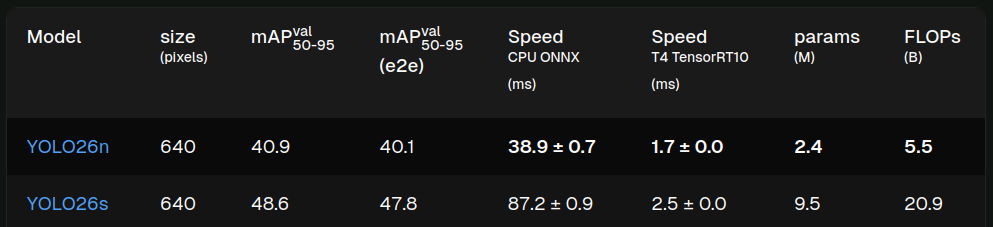

## 1.2 Архитектура (2.5 балла)

Детектор ultralytics - это `DetectionModel`, внутри `det_model.model` - `nn.Sequential` слоев в порядке из yaml-конфига: сначала backbone (`det_model.yaml['backbone']`), потом neck, последний слой - голова `Detect`.

1. Напишите `params_by_block(det_model)`: число параметров в backbone, neck и head
2. Напишите `head_inputs_and_output(det_model, imgsz)`: прогоните dummy-вход `1 x 3 x imgsz x imgsz` в eval-режиме и верните формы карт признаков, которые приходят в `Detect` (forward hook), и выход модели
3. Напечатайте формы выхода (выход - вложенные tuple / dict, функция `shapes` ниже поможет)

**Вопрос.** Распишите блоки: что делает backbone, что делает neck (какие масштабы объединяет), что предсказывает head в каждой точке карты признаков. Почему детектор называют anchor-free? Откуда число 8400 при входе 640? Что значат две ветки выхода `one2many` и `one2one` и почему YOLO26 обходится без NMS? Какая доля параметров в каждом блоке?

In [94]:
def params_by_block(det_model):
    layers = det_model.model
    n_backbone = len(det_model.yaml['backbone'])
    n_neck = len(layers) - n_backbone - 1

    backbone_params = sum(p.numel() for p in layers[:n_backbone].parameters())
    neck_params = sum(p.numel() for p in layers[n_backbone:n_backbone + n_neck].parameters())
    head_params = sum(p.numel() for p in layers[-1].parameters())

    return {'backbone': backbone_params, 'neck': neck_params, 'head': head_params}


def head_inputs_and_output(det_model, imgsz=640):
    layers = det_model.model
    detect = layers[-1]
    feat_shapes = []

    def hook(module, inputs, output):
        feat_shapes.extend(tuple(x.shape) for x in inputs[0])

    handle = detect.register_forward_hook(hook)

    device = next(det_model.parameters()).device
    training = det_model.training
    det_model.eval()

    with torch.no_grad():
        dummy = torch.zeros(1, 3, imgsz, imgsz, device=device)
        out = det_model(dummy)

    handle.remove()
    det_model.train(training)

    return feat_shapes, out

def shapes(obj):
    if isinstance(obj, torch.Tensor):
        return tuple(obj.shape)
    if isinstance(obj, (list, tuple)):
        return [shapes(o) for o in obj]
    if isinstance(obj, dict):
        return {k: shapes(v) for k, v in obj.items()}
    return type(obj).__name__

In [95]:
arch = YOLO(WEIGHTS).model   # свежая копия: у model_coco после predict Conv и BN уже слиты
blocks = params_by_block(arch)
total = sum(p.numel() for p in arch.parameters())
assert set(blocks) == {'backbone', 'neck', 'head'}
assert sum(blocks.values()) == total, (blocks, total)
assert all(v > 0 for v in blocks.values())
assert blocks['head'] == sum(p.numel() for p in arch.model[-1].parameters())

feat_shapes, out = head_inputs_and_output(arch, 640)
assert len(feat_shapes) == 3 and [s[-1] for s in feat_shapes] == [80, 40, 20], feat_shapes   # страйды 8, 16, 32
print({k: f'{v:,} ({v / total:.0%})' for k, v in blocks.items()}, f'total {total:,}')
print('на входе Detect:', feat_shapes)

{'backbone': '1,365,472 (53%)', 'neck': '897,152 (35%)', 'head': '309,656 (12%)'} total 2,572,280
на входе Detect: [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]


In [96]:
print('Формы выхода модели:')
print(shapes(out))

Формы выхода модели:
[(1, 84, 8400), {'one2many': {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]}, 'one2one': {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]}}]


**Ответ:**

- Backbone - извлекает признаки изображения на разных уровнях абстракции.
- Neck - объединяет признаки разных масштабов: мелкие карты 80×80, средние 40×40 и крупные 20×20. Это позволяет обнаруживать объекты разных размеров.
- Head - предсказывает для каждой точки карты признаки объекта, координаты ограничивающей рамки и классы.
Anchor-free - детектор не использует заранее заданные anchor boxes. Он непосредственно предсказывает координаты объектов относительно точек карт признаков.

Число 8400 получается суммированием количества точек на трёх картах признаков при входе 640×640:
$$
80 \cdot 80 + 40 \cdot 40 + 20 \cdot 20 =
6400 + 1600 + 400 = 8400
$$
one2many - ветка обучения, позволяющая одной точке или объекту иметь несколько положительных соответствий. Это улучшает обучение модели.

one2one - ветка, в которой каждому объекту соответствует одно предсказание. Она используется для получения результата без NMS.

YOLO26 использует end-to-end подход с one-to-one назначением соответствий. Благодаря этому модель может выдавать готовые предсказания без дополнительного этапа Non-Maximum Suppression (NMS), который обычно удаляет дублирующиеся рамки.

Параметры нейросети 'backbone': '1,365,472 (53%)', 'neck': '897,152 (35%)', 'head': '309,656 (12%)'.

---
# 2. Данные

## 2.1 Свой датасет (1.5 балла)

Найдите датасет детекции, лучше такой, где классов нет в COCO или COCO-модель работает плохо. Где искать:

- [Roboflow Universe](https://universe.roboflow.com) - тысячи датасетов детекции с экспортом в YOLO / COCO / VOC, нужен бесплатный аккаунт. API-ключ в ноутбук не кладите: скачайте zip руками или читайте ключ из переменной окружения
- [Kaggle Datasets](https://www.kaggle.com/datasets?search=object+detection) - нужен аккаунт и `kaggle.json`, в Kaggle-ноутбуке датасет подключается кнопкой Add Input
- [Hugging Face Hub](https://huggingface.co/datasets?task_categories=task_categories:object-detection) - фильтр object-detection, многие датасеты скачиваются без ключей
- [Open Images V7](https://storage.googleapis.com/openimages/web/index.html) - 600 классов, отдельные классы удобно выгружать через FiftyOne
- GitHub-репозитории статей и учебные датасеты в формате VOC XML / COCO JSON

Требования: открытая лицензия (CC BY, CC0, MIT, Apache и т.п., укажите какая), не PennFudan и не coco8 / coco128, от ~150 картинок, и чтобы обучение с `FAST_MODE = False` укладывалось примерно в час на T4. Если в датасете нет val, сделайте сплит с фиксированным seed. Если картинок очень много, возьмите подмножество и напишите, как выбирали.

Контракт для следующих задач: `records[split]` - список словарей `dict(image=путь, width=..., height=..., boxes=np.ndarray (n, 4) float в пикселях xyxy, labels=np.ndarray (n,) int)`, `CLASSES` - список имен классов, `DATASET_NAME` - название, ссылка и лицензия одной строкой. Боксы с нулевой площадью и выходящие за картинку почистите (обрежьте) и посчитайте, сколько таких было.

Посчитайте статистику: объекты на класс по сплитам, объекты на картинку, размеры боксов (в пикселях или в долях картинки, гистограмма или scatter по классам).

**Вопрос.** Опишите источник, лицензию, классы, размер и сплиты. Что видно из статистики: дисбаланс классов, мелкие объекты, плотные сцены? Какие проблемы разметки заметили?

In [97]:
!unzip 'Aquarium Combined.v6i.coco.zip' -d aquarium

Archive:  Aquarium Combined.v6i.coco.zip
 extracting: aquarium/README.dataset.txt  
 extracting: aquarium/README.roboflow.txt  
   creating: aquarium/test/
 extracting: aquarium/test/IMG_2289_jpeg_jpg.rf.a56bc9be7aed57907c19762cb39801a5.jpg  
 extracting: aquarium/test/IMG_2301_jpeg_jpg.rf.37fbc1665199a72a403b536b0c254df5.jpg  
 extracting: aquarium/test/IMG_2319_jpeg_jpg.rf.be51387731b93b6a7779220ee93ea2f3.jpg  
 extracting: aquarium/test/IMG_2347_jpeg_jpg.rf.2b7a6276ea2120825799cf526ffb1599.jpg  
 extracting: aquarium/test/IMG_2354_jpeg_jpg.rf.cb2166f87ec7c94292497027fec04166.jpg  
 extracting: aquarium/test/IMG_2371_jpeg_jpg.rf.526896a64609c451f462424f1bb04a5d.jpg  
 extracting: aquarium/test/IMG_2379_jpeg_jpg.rf.7dc7331bb2dfe884f129f3782bfb63c9.jpg  
 extracting: aquarium/test/IMG_2380_jpeg_jpg.rf.6042aaf941b7e6e1114ce67ac0960748.jpg  
 extracting: aquarium/test/IMG_2387_jpeg_jpg.rf.3e762c923bd68f7f6b02bf74714b2d60.jpg  
 extracting: aquarium/test/IMG_2395_jpeg_jpg.rf.f6a24153e48f7

In [98]:
DATASET_DIR = DATA_ROOT / 'aquarium'

annotation_files = list(DATASET_DIR.rglob('*_annotations.coco.json'))
if not annotation_files:
    annotation_files = list(DATASET_DIR.rglob('*.json'))

assert annotation_files, (
    f'Не найдены COCO JSON-файлы в {DATASET_DIR}. '
    'Скачайте Aquarium Combined в формате COCO и распакуйте в data/aquarium.'
)

coco_data = {}
for ann_path in annotation_files:
    split_name = ann_path.parent.name.lower()
    if split_name in ('valid', 'validation', 'val'):
        split_name = 'val'

    if split_name not in ('train', 'val', 'test'):
        continue

    with open(ann_path, encoding='utf-8') as f:
        coco_data[split_name] = json.load(f)

assert {'train', 'val'} <= set(coco_data), (
    f'Нужны train и val. Найдены сплиты: {list(coco_data)}'
)

used_ids = {a['category_id'] for d in coco_data.values() for a in d['annotations']}
categories = sorted(
    [c for c in coco_data['train']['categories'] if c['id'] in used_ids],
    key=lambda x: x['id'])

CLASSES = [c['name'] for c in categories]
category_to_label = {c['id']: i for i, c in enumerate(categories)}


for split, data in coco_data.items():
    split_classes = {c['name'] for c in data['categories']}
    assert set(CLASSES) <= split_classes, (
    f'В сплите {split} отличаются классы: {split_classes}')

DATASET_NAME = (
    'Aquarium Combined — '
    'https://universe.roboflow.com/brad-dwyer/aquarium-combined — '
    'CC BY 4.0'
)

records = {}
n_clipped = 0
n_removed = 0

for split, data in coco_data.items():
    images_by_id = {img['id']: img for img in data['images']}
    annotations_by_image = {}
    for ann in data['annotations']:
        annotations_by_image.setdefault(ann['image_id'], []).append(ann)

    split_records = []

    for image_info in data['images']:
        image_name = image_info['file_name']
        candidates = [
            annotation_files[[p.parent.name.lower() for p in annotation_files].index(
                'valid' if split == 'val' else split
            )].parent / image_name
        ] if any(
            p.parent.name.lower() == ('valid' if split == 'val' else split)
            for p in annotation_files
        ) else []

        candidates += [DATASET_DIR / image_name]

        image_path = next((p for p in candidates if p.exists()), None)

        if image_path is None:
            matches = list(DATASET_DIR.rglob(Path(image_name).name))
            if matches:
                image_path = matches[0]

        if image_path is None:
            raise FileNotFoundError(f'Не найден файл изображения: {image_name}')

        width = int(image_info['width'])
        height = int(image_info['height'])

        boxes = []
        labels = []

        for ann in annotations_by_image.get(image_info['id'], []):
            if ann['category_id'] not in category_to_label:
                continue

            x, y, w, h = map(float, ann['bbox'])

            if not np.isfinite([x, y, w, h]).all() or w <= 0 or h <= 0:
                n_removed += 1
                continue

            x1, y1 = x, y
            x2, y2 = x + w, y + h

            clipped = [
                np.clip(x1, 0, width),
                np.clip(y1, 0, height),
                np.clip(x2, 0, width),
                np.clip(y2, 0, height)
            ]

            if not np.allclose([x1, y1, x2, y2], clipped):
                n_clipped += 1

            x1, y1, x2, y2 = clipped

            if x2 <= x1 or y2 <= y1:
                n_removed += 1
                continue

            boxes.append([x1, y1, x2, y2])
            labels.append(category_to_label[ann['category_id']])

        split_records.append({
            'image': str(image_path),
            'width': width,
            'height': height,
            'boxes': np.asarray(boxes, dtype=np.float32).reshape(-1, 4),
            'labels': np.asarray(labels, dtype=np.int64)
        })

    records[split] = split_records

print('Датасет:', DATASET_NAME)
print('Классы:', CLASSES)
print('Изображения по сплитам:', {
    split: len(recs) for split, recs in records.items()
})
print('Боксов обрезано по границам:', n_clipped)
print('Некорректных боксов удалено:', n_removed)

Датасет: Aquarium Combined — https://universe.roboflow.com/brad-dwyer/aquarium-combined — CC BY 4.0
Классы: ['fish', 'jellyfish', 'penguin', 'puffin', 'shark', 'starfish', 'stingray']
Изображения по сплитам: {'val': 127, 'test': 63, 'train': 448}
Боксов обрезано по границам: 13
Некорректных боксов удалено: 2


In [99]:
assert all(n in globals() for n in ('records', 'CLASSES', 'DATASET_NAME')), 'сначала заполните records, CLASSES, DATASET_NAME'
assert {'train', 'val'} <= set(records) and len(CLASSES) > 0 and isinstance(DATASET_NAME, str)
for split, recs in records.items():
    for r in recs:
        assert Path(r['image']).exists() and r['boxes'].shape == (len(r['labels']), 4), r['image']
        assert (r['boxes'][:, 2] > r['boxes'][:, 0]).all() and (r['boxes'][:, 3] > r['boxes'][:, 1]).all(), r['image']
        assert ((r['labels'] >= 0) & (r['labels'] < len(CLASSES))).all(), r['image']
{split: len(recs) for split, recs in records.items()}

{'val': 127, 'test': 63, 'train': 448}

Количество изображений: {'val': 127, 'test': 63, 'train': 448}

Количество объектов каждого класса:

val:
  fish: 459
  jellyfish: 155
  penguin: 104
  puffin: 74
  shark: 57
  starfish: 27
  stingray: 33

test:
  fish: 249
  jellyfish: 154
  penguin: 82
  puffin: 35
  shark: 36
  starfish: 11
  stingray: 15

train:
  fish: 1965
  jellyfish: 385
  penguin: 330
  puffin: 175
  shark: 259
  starfish: 78
  stingray: 136

Объектов на изображение:
val: среднее=7.16, медиана=4.0, максимум=44
test: среднее=9.24, медиана=8.0, максимум=45
train: среднее=7.43, медиана=4.0, максимум=56


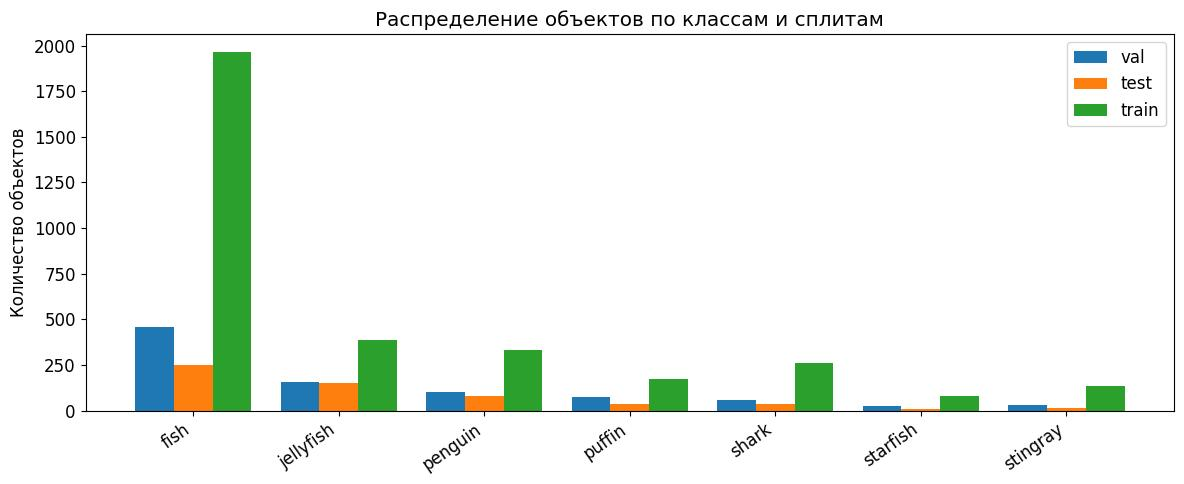

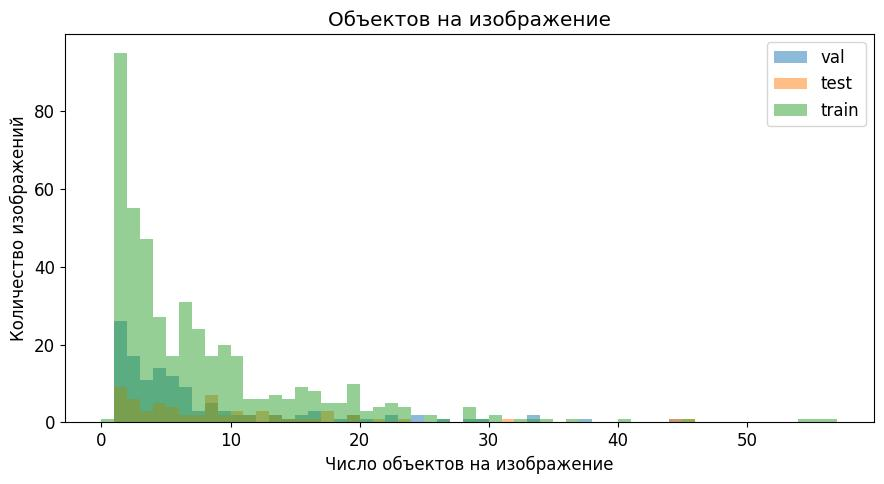

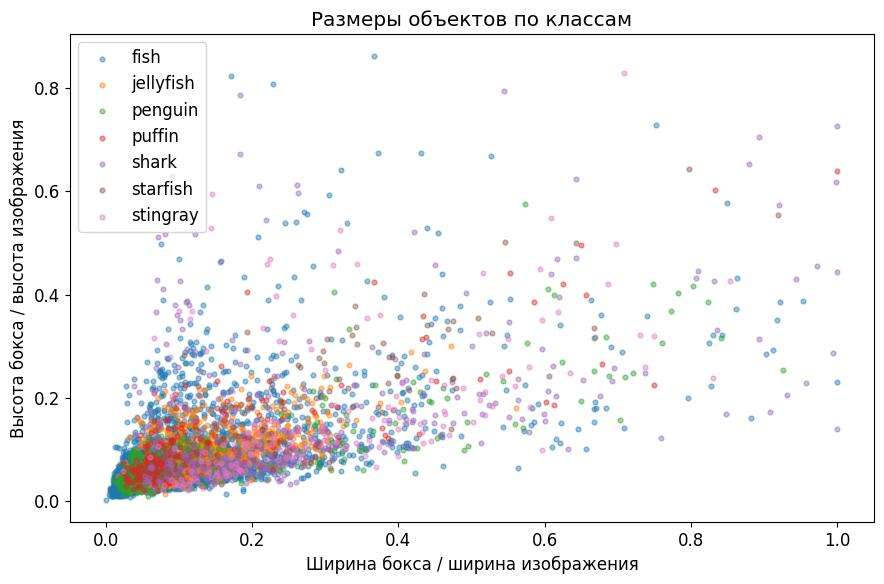


Всего объектов: 4819
Всего изображений: 638
Среднее объектов на изображение по всем сплитам: 7.553291536050157


In [100]:
class_stats = {}
for split, recs in records.items():
    counts = np.zeros(len(CLASSES), dtype=int)
    for r in recs:
        for label in r['labels']:
            counts[int(label)] += 1
    class_stats[split] = counts

print('Количество изображений:', {
    split: len(recs) for split, recs in records.items()
})

print('\nКоличество объектов каждого класса:')
for split, counts in class_stats.items():
    print(f'\n{split}:')
    for name, count in zip(CLASSES, counts):
        print(f'  {name}: {count}')

objects_per_image = {
    split: np.array([len(r['labels']) for r in recs])
    for split, recs in records.items()
}

print('\nОбъектов на изображение:')
for split, values in objects_per_image.items():
    print(
        f'{split}: среднее={values.mean():.2f}, '
        f'медиана={np.median(values):.1f}, '
        f'максимум={values.max()}'
    )

box_sizes = {name: [] for name in CLASSES}

for recs in records.values():
    for r in recs:
        for box, label in zip(r['boxes'], r['labels']):
            x1, y1, x2, y2 = box
            bw = (x2 - x1) / r['width']
            bh = (y2 - y1) / r['height']
            box_sizes[CLASSES[int(label)]].append((bw, bh))

x = np.arange(len(CLASSES))
bar_width = 0.8 / len(class_stats)

fig, ax = plt.subplots(figsize=(12, 5))
for i, (split, counts) in enumerate(class_stats.items()):
    ax.bar(
        x + i * bar_width,
        counts,
        bar_width,
        label=split
    )

ax.set_xticks(x + bar_width * (len(class_stats) - 1) / 2)
ax.set_xticklabels(CLASSES, rotation=35, ha='right')
ax.set_ylabel('Количество объектов')
ax.set_title('Распределение объектов по классам и сплитам')
ax.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
for split, values in objects_per_image.items():
    ax.hist(values, bins=range(0, int(max(values.max() for values in objects_per_image.values())) + 2),
            alpha=0.5, label=split)

ax.set_xlabel('Число объектов на изображение')
ax.set_ylabel('Количество изображений')
ax.set_title('Объектов на изображение')
ax.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 6))
for name, sizes in box_sizes.items():
    if sizes:
        sizes = np.asarray(sizes)
        ax.scatter(sizes[:, 0], sizes[:, 1], s=12, alpha=0.45, label=name)

ax.set_xlabel('Ширина бокса / ширина изображения')
ax.set_ylabel('Высота бокса / высота изображения')
ax.set_title('Размеры объектов по классам')
ax.legend()
plt.tight_layout()
plt.show()

all_counts = np.concatenate(list(class_stats.values()))
print('\nВсего объектов:', int(all_counts.sum()))
print('Всего изображений:', sum(len(v) for v in records.values()))
print('Среднее объектов на изображение по всем сплитам:',
      sum(len(r['labels']) for v in records.values() for r in v) /
      sum(len(v) for v in records.values()))

**Ответ:**
В качестве датасета выбран Aquarium Combined из Roboflow Universe: https://universe.roboflow.com/brad-dwyer/aquarium-combined. Лицензия - CC BY 4.0, допускающая использование и распространение данных с указанием авторства.

Класс  creatures вероятно является базовым классом, он присутвует в аннотации, но у этого класса нет объектов, поэтому я его уюрала из статистики.

Здесь заметен сильный дисбаланс: рыбы составляют больше половины всех объектов, а морских звёзд примерно в 23 раза меньше. Поэтому модель может лучше обучаться на классе fish и хуже распознавать редкие классы, например starfish и stingray.

Плотность сцен
- Train: среднее 7.43 объекта на изображение, медиана 4, максимум 56.
- Val: среднее 7.16, медиана 4, максимум 44.
- Test: среднее 9.24, медиана 8, максимум 45.
Это говорит о том, что на изображениях часто присутствует несколько объектов одновременно. Есть и достаточно плотные сцены, где находится несколько десятков объектов. Особенно интересно, что в test среднее и медиана выше, чем в train: распределение объектов между сплитами немного различается.

Также заметно довольно много маленьких объектов, которые вероятно сложно будет детектировать модели.

## 2.2 Формат разметки (2.5 балла)

ultralytics ждет YOLO-формат: на каждую картинку `images/<split>/<имя>.jpg` есть `labels/<split>/<имя>.txt`, в нем строка на объект `class cx cy w h`, координаты центра и размеры нормированы на ширину и высоту картинки, плюс `data.yaml` с путями и именами классов.

1. Напишите `to_yolo` и `from_yolo` (6 знаков после запятой, пустая разметка - пустой текст)
2. Напишите `export_split`: копирует картинки и пишет txt-разметку сплита в `YOLO_ROOT`
3. Прочитайте разметку обратно из txt-файлов (`from_yolo`) и нарисуйте боксы на 3-4 картинках: так ловятся перепутанные оси и ненормированные координаты

Если ваш датасет уже в YOLO-формате, сделайте обратную конвертацию YOLO -> COCO JSON (`to_coco` / `from_coco` своим кодом) и проверку туда-обратно на всем датасете, `to_yolo` / `from_yolo` все равно реализуйте: на них открытые тесты.

**Вопрос.** Что проверяет тест туда-обратно и чего он не ловит? Какие ошибки конвертации вы бы заметили только на картинке?

In [101]:
def to_yolo(boxes, labels, width, height):
    boxes = np.asarray(boxes, dtype=np.float32).reshape(-1, 4)
    labels = np.asarray(labels, dtype=np.int64).reshape(-1)

    if len(boxes) != len(labels):
        raise ValueError("Количество боксов и меток должно совпадать")
    if width <= 0 or height <= 0:
        raise ValueError("Размеры изображения должны быть положительными")

    lines = []
    for box, label in zip(boxes, labels):
        x1, y1, x2, y2 = box
        cx = ((x1 + x2) / 2) / width
        cy = ((y1 + y2) / 2) / height
        w = (x2 - x1) / width
        h = (y2 - y1) / height
        lines.append(f"{label} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}")

    return "\n".join(lines)


def from_yolo(text, width, height):
    if not text.strip():
        return np.zeros((0, 4), dtype=np.float32), np.zeros(0, dtype=np.int64)

    boxes = []
    labels = []

    for line in text.strip().splitlines():
        values = line.split()
        if len(values) != 5:
            raise ValueError(f"Некорректная строка разметки: {line}")

        label, cx, cy, w, h = values
        label = int(label)
        cx, cy, w, h = map(float, (cx, cy, w, h))

        x1 = (cx - w / 2) * width
        y1 = (cy - h / 2) * height
        x2 = (cx + w / 2) * width
        y2 = (cy + h / 2) * height

        boxes.append([x1, y1, x2, y2])
        labels.append(label)

    return np.asarray(boxes, dtype=np.float32).reshape(-1, 4), np.asarray(labels, dtype=np.int64)

In [102]:
t = to_yolo(np.array([[10, 20, 110, 70]]), np.array([2]), 200, 100)
assert t.split() == ['2', '0.300000', '0.450000', '0.500000', '0.500000'], t
assert to_yolo(np.zeros((0, 4)), np.zeros(0, dtype=np.int64), 640, 480).strip() == ''
b, l = from_yolo('', 640, 480)
assert b.shape == (0, 4) and l.shape == (0,)
b, l = from_yolo('1 0.5 0.5 0.25 0.5\n0 0.1 0.2 0.1 0.2\n', 400, 200)
assert np.allclose(b, [[150, 50, 250, 150], [20, 20, 60, 60]], atol=1e-3) and l.tolist() == [1, 0], (b, l)

rng = np.random.default_rng(0)
for _ in range(100):
    W, H = rng.integers(32, 2000, size=2)
    n = int(rng.integers(1, 30))
    xy = rng.uniform(0, 1, (n, 2)) * [W, H]
    boxes = np.concatenate([xy, np.minimum(xy + rng.uniform(1, 0.5 * min(W, H), (n, 2)), [W, H])], axis=1)
    labels = rng.integers(0, 5, n)
    b, l = from_yolo(to_yolo(boxes, labels, W, H), W, H)
    assert np.allclose(b, boxes, atol=1e-5 * max(W, H) + 1e-3) and (l == labels).all()
print('to_yolo / from_yolo: ok')

to_yolo / from_yolo: ok


In [103]:
YOLO_ROOT = DATA_ROOT / 'yolo'

def export_split(recs, split):
    images_dir = YOLO_ROOT / 'images' / split
    labels_dir = YOLO_ROOT / 'labels' / split

    images_dir.mkdir(parents=True, exist_ok=True)
    labels_dir.mkdir(parents=True, exist_ok=True)

    for r in recs:
        image_path = Path(r['image'])
        image_name = image_path.name

        shutil.copy2(image_path, images_dir / image_name)

        label_text = to_yolo(
            r['boxes'],
            r['labels'],
            r['width'],
            r['height']
        )

        label_path = labels_dir / f'{image_path.stem}.txt'
        label_path.write_text(label_text, encoding='utf-8')

order = np.random.default_rng(SEED).permutation(len(records['train']))
train_recs = [records['train'][i] for i in order[:N_TRAIN_FAST]] if FAST_MODE else records['train']
shutil.rmtree(YOLO_ROOT, ignore_errors=True)   # старые файлы и *.cache ultralytics от прошлых прогонов
splits = {'train': train_recs, **{s: r for s, r in records.items() if s != 'train'}}
for split, recs in splits.items():
    export_split(recs, split)
DATA_YAML = YOLO_ROOT / 'data.yaml'
DATA_YAML.write_text(f'path: {YOLO_ROOT.resolve().as_posix()}\n'
                     + ''.join(f'{s}: images/{s}\n' for s in splits)
                     + 'names:\n' + ''.join(f'  {i}: {n}\n' for i, n in enumerate(CLASSES)))
for split, recs in splits.items():
    assert len(list((YOLO_ROOT / 'labels' / split).glob('*.txt'))) == len(recs), split
FINAL_SPLIT = 'test' if 'test' in records else 'val'   # на нем считаются бейзлайн (3.1) и финальные метрики (4.2)
print(DATA_YAML.read_text())

path: /content/data/yolo
train: images/train
val: images/val
test: images/test
names:
  0: fish
  1: jellyfish
  2: penguin
  3: puffin
  4: shark
  5: starfish
  6: stingray



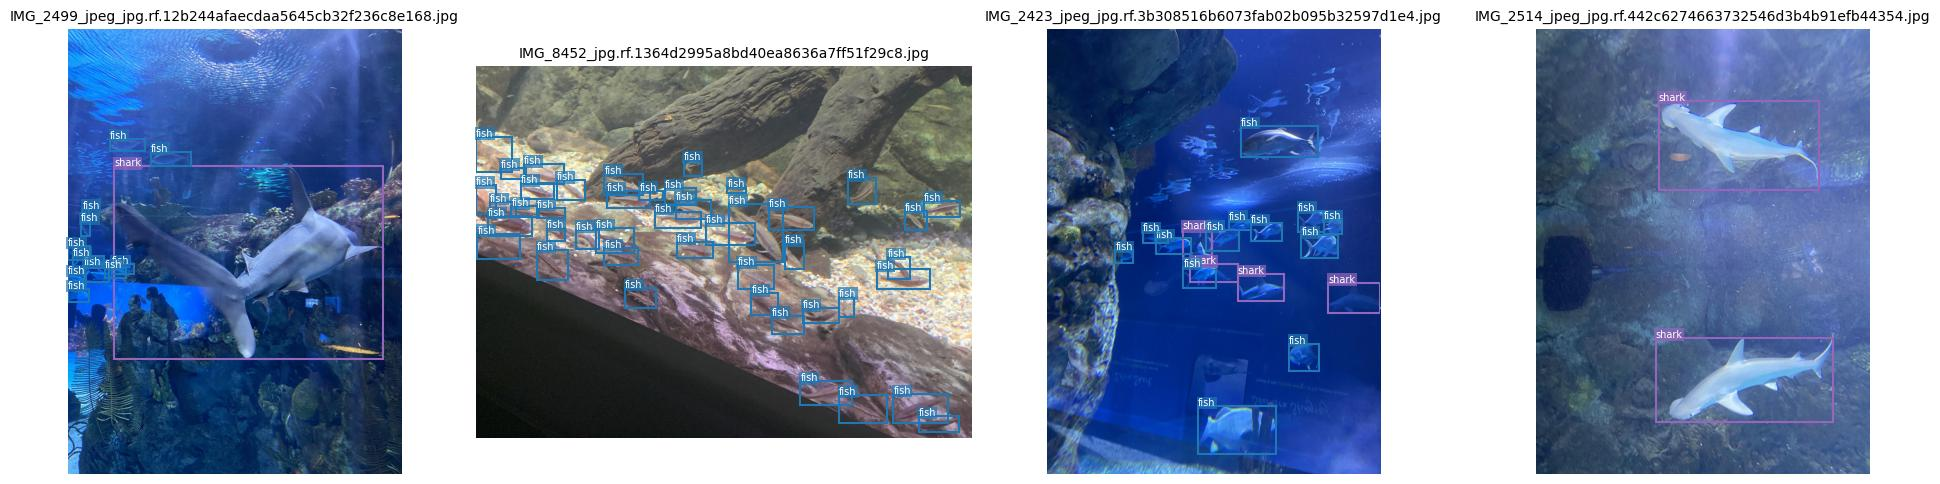

Проверка конвертации пройдена


In [104]:
for split, recs in splits.items():
    for r in recs:
        image_path = Path(r['image'])
        label_path = YOLO_ROOT / 'labels' / split / f'{image_path.stem}.txt'

        text = label_path.read_text(encoding='utf-8')
        boxes, labels = from_yolo(text, r['width'], r['height'])

        assert boxes.shape == r['boxes'].shape
        tol = max(r['width'], r['height']) * 1e-6 + 1e-5
        assert np.allclose(boxes, r['boxes'], atol=tol)
        assert np.array_equal(labels, r['labels'])
        assert np.array_equal(labels, r['labels'])

visual_recs = splits[FINAL_SPLIT][:4]

fig, axes = plt.subplots(1, len(visual_recs), figsize=(5 * len(visual_recs), 5))

if len(visual_recs) == 1:
    axes = [axes]

for ax, r in zip(axes, visual_recs):
    image_path = Path(r['image'])
    image = np.array(Image.open(image_path).convert('RGB'))

    label_path = YOLO_ROOT / 'labels' / FINAL_SPLIT / f'{image_path.stem}.txt'
    text = label_path.read_text(encoding='utf-8')
    boxes, labels = from_yolo(text, r['width'], r['height'])

    draw_boxes(ax, image, boxes, labels, CLASSES, title=image_path.name)

plt.tight_layout()
plt.show()

print('Проверка конвертации пройдена')

**Ответ:**

Тест туда-обратно проверяет, что после преобразования координат из формата XYXY в YOLO и обратно сохраняются положения и размеры bounding boxes, а также идентификаторы классов. Он помогает обнаружить ошибки в формулах нормализации, восстановлении координат и порядке классов.

Однако такой тест не обнаруживает ошибки в исходной разметке, например неправильно нарисованные bounding boxes или неверно указанные классы. Также он не гарантирует, что координаты соответствуют реальным объектам на изображении. Такие ошибки можно заметить при визуальной проверке: рамки могут быть смещены, иметь неправильный размер, выходить за границы объектов или охватывать не тот объект.

---
# 3. Бейзлайн

## 3.1 До дообучения (2 балла)

Нужна точка отсчета, без нее непонятно, сколько дало дообучение.

Все считается на `FINAL_SPLIT` (test, если он есть, иначе val) - на том же сплите, что и финальные метрики в 4.2.

1. Прогоните COCO-модель без дообучения. Если в COCO есть совпадающие классы (person, car, dog и т.п.), переназначьте их индексы на ваши и посчитайте mAP50 функцией `evaluate_map50`. Если совпадающих классов нет, покажите, что модель предсказывает на ваших картинках, и объясните, почему mAP равен нулю
2. Напишите тривиальный бейзлайн своим кодом без нейросетей: средние боксы класса из train на сетке, порог по цвету + связные компоненты (`scipy.ndimage.label`), скользящее окно с простым признаком и т.п. Параметры можно подбирать по train, но не по val. Оцените его через `evaluate_map50`. Бейзлайн не обязан быть хорошим

В первой ячейке задайте `coco_map50`, `BASELINE` соберется сам из него и результатов эвристики.

**Вопрос.** Почему у COCO-модели такое качество на ваших данных? На каких классах эвристика работает, а на каких нет и почему?

Совпадающих классов с COCO нет
COCO mAP50: 0.0


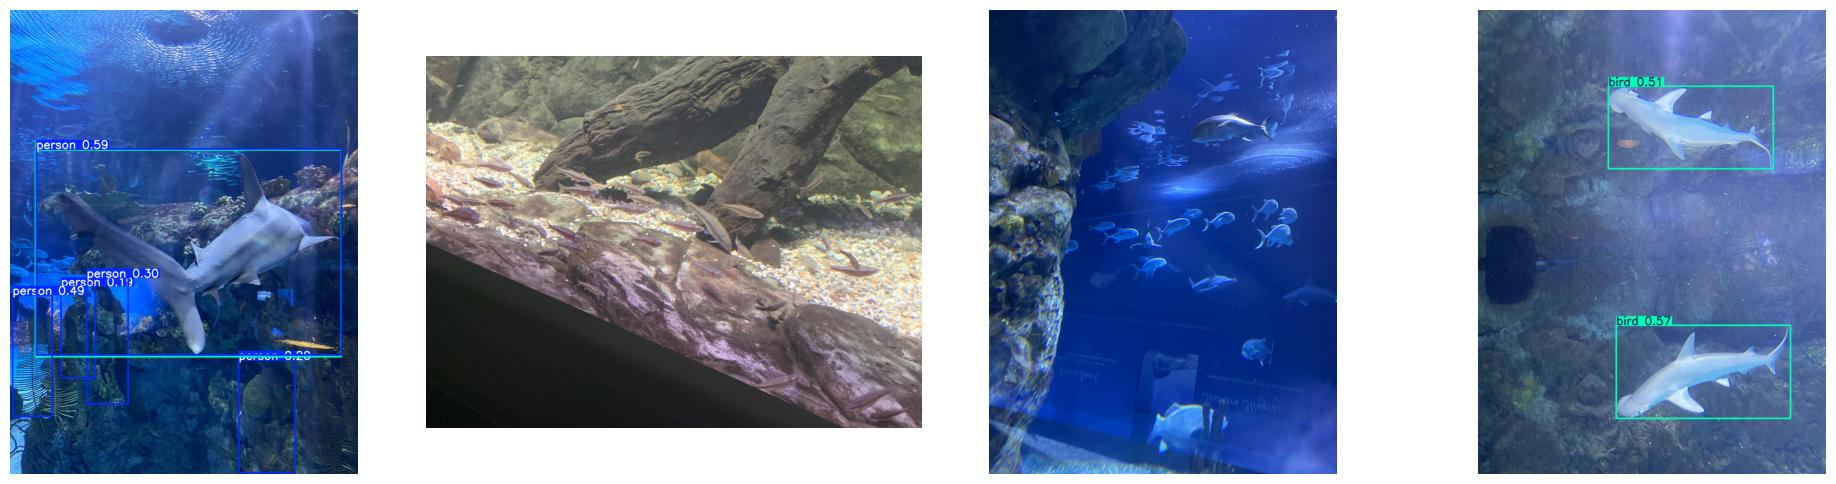

In [105]:
coco_names = model_coco.names
coco_name_to_id = {str(v).lower(): int(k) for k, v in coco_names.items()}
class_mapping = {
    coco_id: class_id
    for class_id, name in enumerate(CLASSES)
    if (coco_id := coco_name_to_id.get(name.lower())) is not None
}

if class_mapping:
    coco_preds = predict_records(model_coco, records[FINAL_SPLIT], conf=0.001)
    for pred in coco_preds:
        keep = np.isin(pred['labels'], list(class_mapping))
        pred['boxes'] = pred['boxes'][keep]
        pred['scores'] = pred['scores'][keep]
        pred['labels'] = np.array([class_mapping[int(x)] for x in pred['labels'][keep]])
    coco_map50, coco_aps = evaluate_map50(coco_preds, records[FINAL_SPLIT], len(CLASSES))
    print('Совпадающие классы:', {CLASSES[v]: coco_names[k] for k, v in class_mapping.items()})
    print('COCO mAP50:', coco_map50)
    print('AP50 по классам:', dict(zip(CLASSES, coco_aps)))
else:
    coco_map50 = 0.0
    print('Совпадающих классов с COCO нет')
    print('COCO mAP50:', coco_map50)

    sample_records = records[FINAL_SPLIT][:4]
    results = model_coco.predict(
        [str(r['image']) for r in sample_records],
        conf=0.15,
        imgsz=IMGSZ,
        device=DEVICE,
        verbose=False
    )

    fig, axes = plt.subplots(1, len(results), figsize=(5 * len(results), 5))
    if len(results) == 1:
        axes = [axes]

    for ax, result in zip(axes, results):
        ax.imshow(result.plot()[..., ::-1])
        ax.set_axis_off()

    plt.tight_layout()
    plt.show()

In [106]:
HEUR = dict(thr=0.15, min_frac=0.002, max_frac=0.6, top_k=3, temp=1.0, small=200)
HEUR_STATE = {}


def load_small(image_path, side=None):
    side = side or HEUR['small']
    im = Image.open(image_path).convert('RGB')
    W, H = im.size
    s = side / max(W, H)
    sw, sh = max(1, round(W * s)), max(1, round(H * s))
    arr = np.asarray(im.resize((sw, sh), Image.BILINEAR), dtype=np.float32) / 255.0
    return arr, W / sw, H / sh


def box_features(arr, box):
    h_img, w_img = arr.shape[:2]
    x1, y1, x2, y2 = [float(v) for v in box]
    bw, bh = max(x2 - x1, 1e-3), max(y2 - y1, 1e-3)
    cx1 = int(np.clip(np.floor(x1 + 0.2 * bw), 0, w_img - 1))
    cy1 = int(np.clip(np.floor(y1 + 0.2 * bh), 0, h_img - 1))
    cx2 = int(np.clip(max(np.ceil(x2 - 0.2 * bw), cx1 + 1), 1, w_img))
    cy2 = int(np.clip(max(np.ceil(y2 - 0.2 * bh), cy1 + 1), 1, h_img))
    crop = arr[cy1:cy2, cx1:cx2].reshape(-1, 3)
    mx, mn = crop.max(1), crop.min(1)
    sat = float(((mx - mn) / (mx + 1e-6)).mean())
    rgb = crop.mean(0)
    return np.array([rgb[0], rgb[1], rgb[2], sat, math.log(bw / bh), 0.5 * math.log(bw * bh / (w_img * h_img))],
                    dtype=np.float32)


def foreground_components(arr):
    bg = np.median(arr.reshape(-1, 3), axis=0)
    dist = np.sqrt(((arr - bg) ** 2).sum(-1)) / math.sqrt(3)
    dist = ndimage.gaussian_filter(dist, 1.0)
    mask = dist > HEUR['thr']
    mask = ndimage.binary_opening(mask, iterations=1)
    mask = ndimage.binary_closing(mask, iterations=2)
    lab, _ = ndimage.label(mask)
    out = []
    for k, sl in enumerate(ndimage.find_objects(lab), start=1):
        if sl is None:
            continue
        comp = lab[sl] == k
        frac = comp.sum() / mask.size
        if frac < HEUR['min_frac'] or frac > HEUR['max_frac']:
            continue
        out.append(([sl[1].start, sl[0].start, sl[1].stop, sl[0].stop], float(dist[sl][comp].mean())))
    return out


def class_probs(feat):
    if not HEUR_STATE:
        return None
    z = (feat - HEUR_STATE['mean']) / HEUR_STATE['std']
    d2 = ((z[None] - HEUR_STATE['centroids']) ** 2).sum(1)
    logits = -d2 / (2 * HEUR['temp']) + HEUR_STATE['log_prior']
    logits = np.where(HEUR_STATE['valid'], logits, -np.inf)
    logits = logits - logits.max()
    p = np.exp(logits)
    return p / p.sum()


def heuristic_detect(image_path):
    arr, sx, sy = load_small(image_path)
    boxes, scores, labels = [], [], []
    for box, contrast in foreground_components(arr):
        probs = class_probs(box_features(arr, box))
        if probs is None:
            hyp = [(0, 1.0)]
        else:
            top = np.argsort(-probs)[:HEUR['top_k']]
            hyp = [(int(c), float(probs[c])) for c in top if probs[c] > 0.02]
        for c, p in hyp:
            boxes.append([box[0] * sx, box[1] * sy, box[2] * sx, box[3] * sy])
            scores.append(contrast * p)
            labels.append(c)
    return dict(boxes=np.asarray(boxes, dtype=np.float32).reshape(-1, 4),
                scores=np.asarray(scores, dtype=np.float32).reshape(-1),
                labels=np.asarray(labels, dtype=np.int64).reshape(-1))

In [107]:
rng_h = np.random.default_rng(SEED)
feats = [[] for _ in CLASSES]
for r in records['train']:
    arr, sx, sy = load_small(r['image'])
    for box, label in zip(r['boxes'], r['labels']):
        feats[int(label)].append(box_features(arr, [box[0] / sx, box[1] / sy, box[2] / sx, box[3] / sy]))

counts = np.array([len(f) for f in feats])
all_f = np.concatenate([np.stack(f) for f in feats if f])
mean_all, std_all = all_f.mean(0), all_f.std(0) + 1e-6
HEUR_STATE.update(
    valid=counts > 0, mean=mean_all, std=std_all,
    centroids=np.stack([((np.stack(f) - mean_all) / std_all).mean(0) if f else np.zeros(all_f.shape[1]) for f in feats]),
    log_prior=np.log(np.maximum(counts, 1) / counts.sum()))

tune_recs = [records['train'][i] for i in rng_h.permutation(len(records['train']))[:150]]
best_map, best_params = -1.0, None
for thr in (0.08, 0.12, 0.16, 0.22):
    for min_frac in (0.001, 0.004):
        for temp in (0.5, 2.0):
            HEUR.update(thr=thr, min_frac=min_frac, temp=temp)
            m, _ = evaluate_map50([heuristic_detect(r['image']) for r in tune_recs], tune_recs, len(CLASSES))
            if m > best_map:
                best_map, best_params = m, dict(thr=thr, min_frac=min_frac, temp=temp)
HEUR.update(best_params)
print('объектов на класс в train:', dict(zip(CLASSES, counts.tolist())))
print('лучшие параметры (по train):', best_params, f'mAP50 на подвыборке train: {best_map:.4f}')

объектов на класс в train: {'fish': 1965, 'jellyfish': 385, 'penguin': 330, 'puffin': 175, 'shark': 259, 'starfish': 78, 'stingray': 136}
лучшие параметры (по train): {'thr': 0.12, 'min_frac': 0.001, 'temp': 0.5} mAP50 на подвыборке train: 0.0058


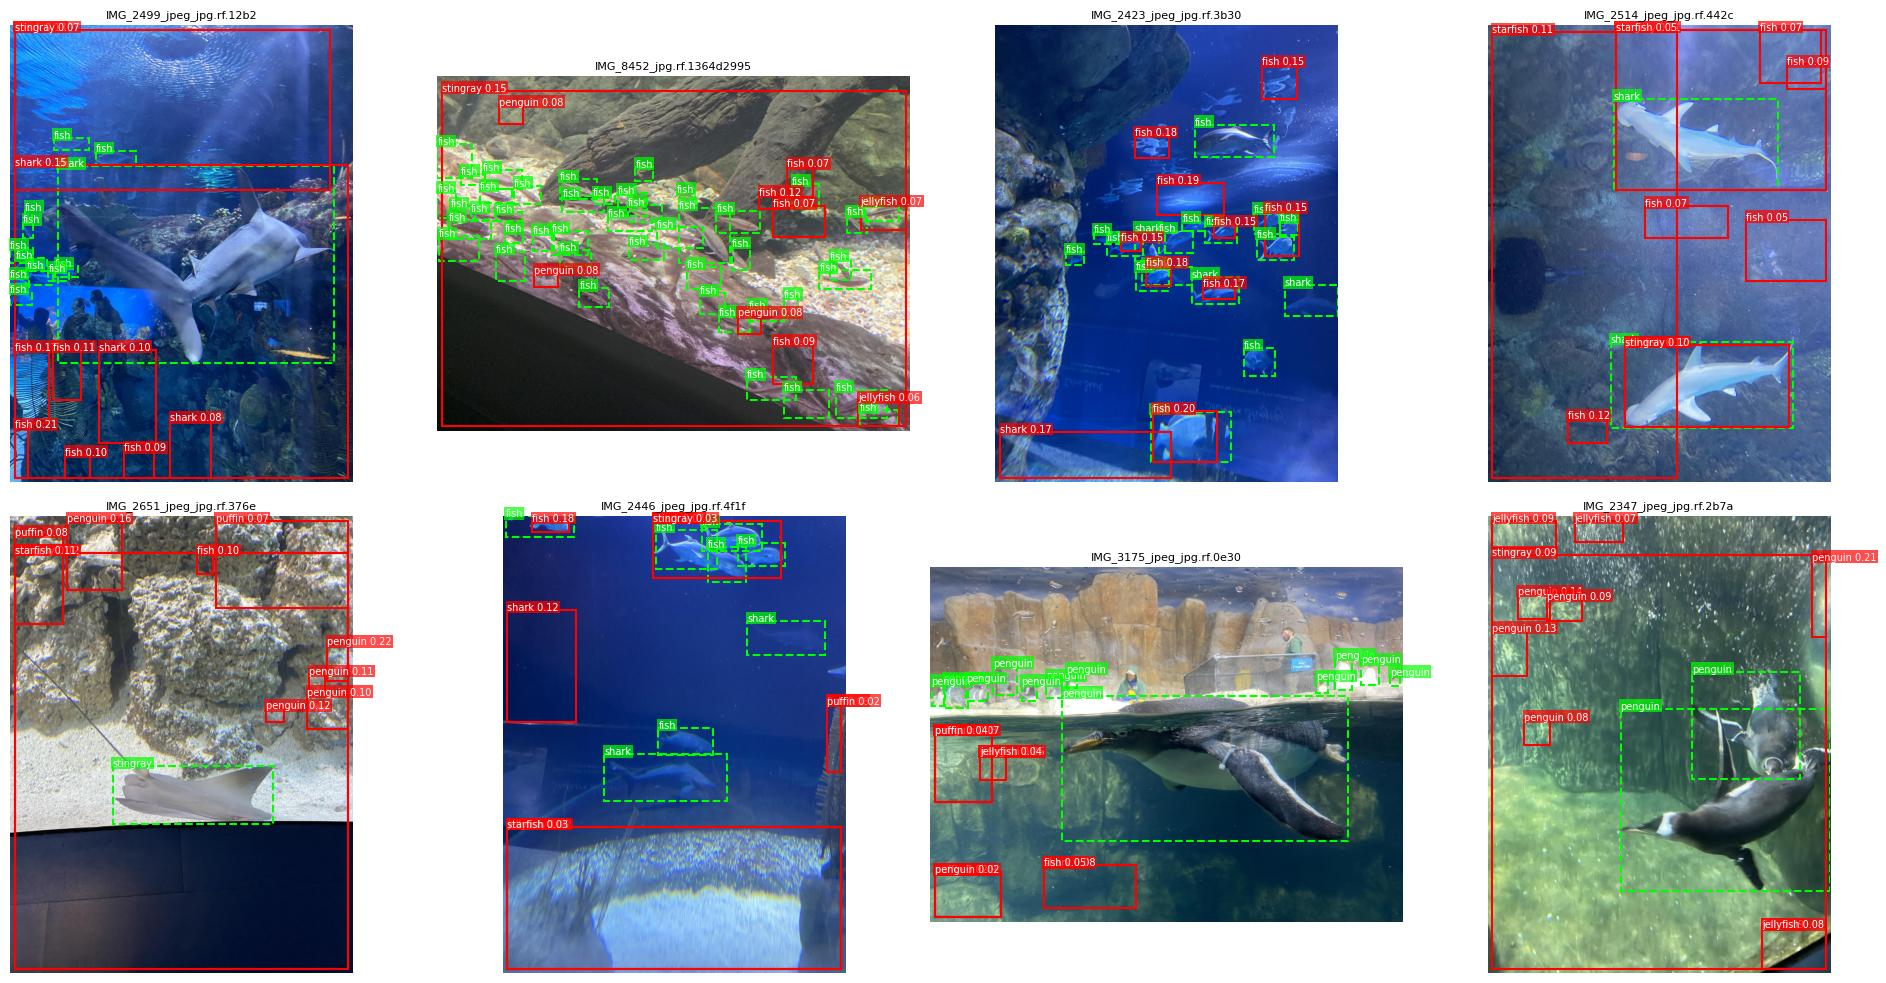

{'split': 'test',
 'coco_map50': 0.0,
 'heuristic_map50': 0.003273900712594559,
 'heuristic_ap50_per_class': {'fish': 0.006374902085221568,
  'jellyfish': 0.006885074724270705,
  'penguin': 0.0,
  'puffin': 0.0007722007722007722,
  'shark': 0.004339672861014323,
  'starfish': 0.004545454545454546,
  'stingray': 0.0}}

In [108]:
start = time.perf_counter()
heuristic_preds = [heuristic_detect(r['image']) for r in records[FINAL_SPLIT]]
heuristic_map50, heuristic_aps = evaluate_map50(heuristic_preds, records[FINAL_SPLIT], len(CLASSES))
RUN_TIMES['heuristic'] = time.perf_counter() - start
BASELINE = dict(split=FINAL_SPLIT, coco_map50=coco_map50, heuristic_map50=heuristic_map50,
                heuristic_ap50_per_class=dict(zip(CLASSES, heuristic_aps)))
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
for ax, r, p in zip(axes.ravel(), records[FINAL_SPLIT][:8], heuristic_preds[:8]):
    img = np.asarray(Image.open(r['image']).convert('RGB'))
    draw_boxes(ax, img, r['boxes'], r['labels'], CLASSES, color='lime', linestyle='--')   # разметка
    top = np.argsort(-p['scores'])[:10]
    draw_boxes(ax, None, p['boxes'][top], p['labels'][top], CLASSES, scores=p['scores'][top], color='red')   # эвристика
    ax.set_title(Path(r['image']).name[:25], fontsize=8)
plt.tight_layout()
plt.show()
BASELINE

**Ответ:**

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Дообучите модель из 1.1 на своем датасете. Гиперпараметры выберите осмысленно и объясните: число эпох, `imgsz` (размер объектов!), `batch` (память T4), оптимизатор и lr, аугментации (например, для микроскопии и снимков сверху уместен `flipud`, для текста и дорожных знаков - нет), `patience`. Список аргументов - в [документации](https://docs.ultralytics.com/modes/train/#train-settings). Валидацию во время обучения оставьте включенной: нужны val loss.

Заполните `TRAIN_ARGS`, обучение запускает готовая `train_yolo`. Нарисуйте кривые train и val loss по эпохам из `results.csv` (все компоненты loss, которые там есть) и mAP50 на val по эпохам. Напечатайте время обучения и устройство.

**Вопрос.** Почему такие гиперпараметры? Есть ли переобучение по кривым (train loss падает, val loss растет)? Хватило ли эпох?

In [109]:
def train_yolo(name, weights=WEIGHTS, **args):
    # обертка над model.train: свой каталог прогона, замер времени; возвращает (модель, секунды, каталог прогона)
    model = YOLO(weights)
    start = time.perf_counter()
    model.train(data=str(DATA_YAML), device=DEVICE, workers=WORKERS, project=str(RUNS.resolve()), name=name,
                exist_ok=True, verbose=False, **args)
    return model, time.perf_counter() - start, Path(model.trainer.save_dir)


def read_results(run_dir):
    # results.csv ultralytics -> dict(колонка -> np.array по эпохам)
    with open(Path(run_dir) / 'results.csv', newline='') as f:
        rows = list(csv.DictReader(f))
    return {k.strip(): np.array([float(r[k]) for r in rows]) for k in rows[0]}

In [110]:
TRAIN_ARGS = dict(
    epochs=EPOCHS,
    imgsz=IMGSZ,
    batch=BATCH,
    optimizer='AdamW',
    lr0=0.001, lrf=0.01,
    cos_lr=True,
    patience=0 if FAST_MODE else 15,
    warmup_epochs=1 if FAST_MODE else 3,
    close_mosaic=0 if FAST_MODE else 10,
    fliplr=0.5, flipud=0.0,
    mosaic=1.0, degrees=0.0,
    seed=SEED, deterministic=True,
    cache='ram', plots=True, val=True,
)
model_ft, RUN_TIMES['train'], run_dir = train_yolo('finetune', **TRAIN_ARGS)
print(f'обучение: {RUN_TIMES["train"]:.0f} s на {DEVICE_NAME}, каталог {run_dir}')

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=data/yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=finetune, nbs=64, nms=None, opset=None, optimize=False, optimizer=AdamW

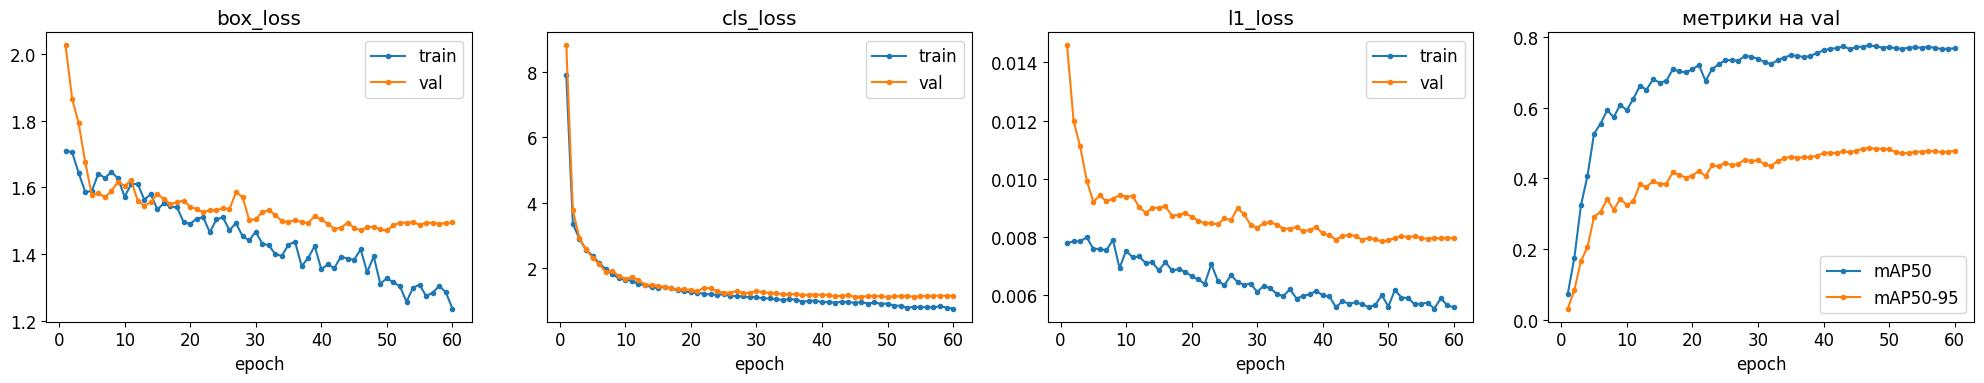

время обучения: 519 s (8.7 мин), устройство: Tesla T4
эпох выполнено: 60 из 60; лучший val mAP50 = 0.7757 на эпохе 47


In [111]:
res = read_results(run_dir)
epochs_x = res['epoch'] if 'epoch' in res else np.arange(1, len(next(iter(res.values()))) + 1)
loss_names = sorted({k.split('/', 1)[1] for k in res if k.startswith('train/')})
loss_names = [n for n in loss_names if res['train/' + n].any() or res.get('val/' + n, np.zeros(1)).any()]

fig, axes = plt.subplots(1, len(loss_names) + 1, figsize=(5 * (len(loss_names) + 1), 4))
for ax, name in zip(axes, loss_names):
    ax.plot(epochs_x, res['train/' + name], marker='o', ms=3, label='train')
    if 'val/' + name in res:
        ax.plot(epochs_x, res['val/' + name], marker='o', ms=3, label='val')
    ax.set_title(name)
    ax.set_xlabel('epoch')
    ax.legend()
map_ax = axes[-1]
map_ax.plot(epochs_x, res['metrics/mAP50(B)'], marker='o', ms=3, label='mAP50')
map_ax.plot(epochs_x, res['metrics/mAP50-95(B)'], marker='o', ms=3, label='mAP50-95')
map_ax.set_title('метрики на val')
map_ax.set_xlabel('epoch')
map_ax.legend()
plt.tight_layout()
plt.show()

print(f'время обучения: {RUN_TIMES["train"]:.0f} s ({RUN_TIMES["train"] / 60:.1f} мин), устройство: {DEVICE_NAME}')
print(f'эпох выполнено: {len(epochs_x)} из {TRAIN_ARGS["epochs"]}; лучший val mAP50 = {res["metrics/mAP50(B)"].max():.4f} '
      f'на эпохе {int(epochs_x[res["metrics/mAP50(B)"].argmax()])}')

**Ответ:**

- **Аугментация изображений (`fliplr=0.5`, `flipud=0.0`).** Используется горизонтальное отражение с вероятностью 50%. Рыбы и пингвины на фотографиях преимущественно сняты сбоку, поэтому горизонтальный флип сохраняет реалистичность изображений. Вертикальное отражение отключено, так как оно может создавать неестественные положения объектов.

- **Ранняя остановка (`patience`).** Предусмотрена остановка обучения при отсутствии улучшения метрики `mAP` на валидационной выборке. В режиме `FAST_MODE` используется всего 2 эпохи, поэтому ранняя остановка отключена (`patience=0`).

- **Размер изображения (`imgsz=640`).** Используется разрешение 640 × 640 пикселей. Это важно, поскольку в датасете присутствует много мелких объектов, а медианный размер bounding box составляет около 10% от стороны изображения.

- **Размер батча (`batch=16`).** Выбран размер батча 16. При разрешении 640 × 640 такой размер помещается в видеопамять GPU NVIDIA T4 при использовании автоматического смешанного точностного режима (AMP).

- **Оптимизатор (`optimizer='AdamW'`).** Выбран AdamW, поскольку он обеспечивает устойчивое обновление весов при дообучении предобученной модели на небольшом датасет(да и в целом стандартно его использовать).

- **Скорость обучения (`lr0=0.001`, `lrf=0.01`).** Используется небольшая начальная скорость обучения, чтобы сохранить полезные признаки, полученные моделью при предварительном обучении. К концу обучения learning rate уменьшается до 1% от начального значения, то есть в 100 раз.

## 4.2 Метрики (3 балла)

Посчитайте метрики лучших весов (`best.pt`) через `model.val` на val и, если есть, на test: mAP50, mAP50-95, precision и recall в целом и по классам, PR-кривая и confusion matrix (картинки, которые ultralytics сохраняет в каталог валидации, можно показать через `plt.imread`). Заполните `FINAL` в формате ниже на `FINAL_SPLIT` (тот же сплит, что у бейзлайна в 3.1). Для сверки посчитайте mAP50 по предсказаниям `predict_records` функцией `evaluate_map50`.

**Вопрос.** Какие классы даются хуже и почему (размер, число примеров, похожесть на другие классы)? Что показывает confusion matrix, в частности строка и столбец background? Почему mAP50-95 сильно ниже mAP50? Насколько ваш mAP50 совпал с ultralytics и почему может не совпадать?

In [112]:
best = YOLO(run_dir / 'weights' / 'best.pt')


def val_metrics(model, split, name, **kw):
    return model.val(data=str(DATA_YAML), split=split, imgsz=IMGSZ, batch=BATCH, device=DEVICE, workers=WORKERS,
                     project=str(RUNS.resolve()), name=name, exist_ok=True, verbose=False, **kw)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,391,193 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2631.2±1012.0 MB/s, size: 612.4 KB)
val: Scanning /content/data/yolo/labels/val.cache... 127 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 127/127 44.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 1.8it/s 4.6s
                   all        127        909      0.768      0.719      0.775      0.488
Speed: 3.9ms preprocess, 7.2ms inference, 0.0ms loss, 3.5ms postprocess per image
Results saved to /content/runs_hw2/eval_val
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,391,193 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1858.7±716.0 MB/s, size: 994.3 KB)
val: Scanning /content/

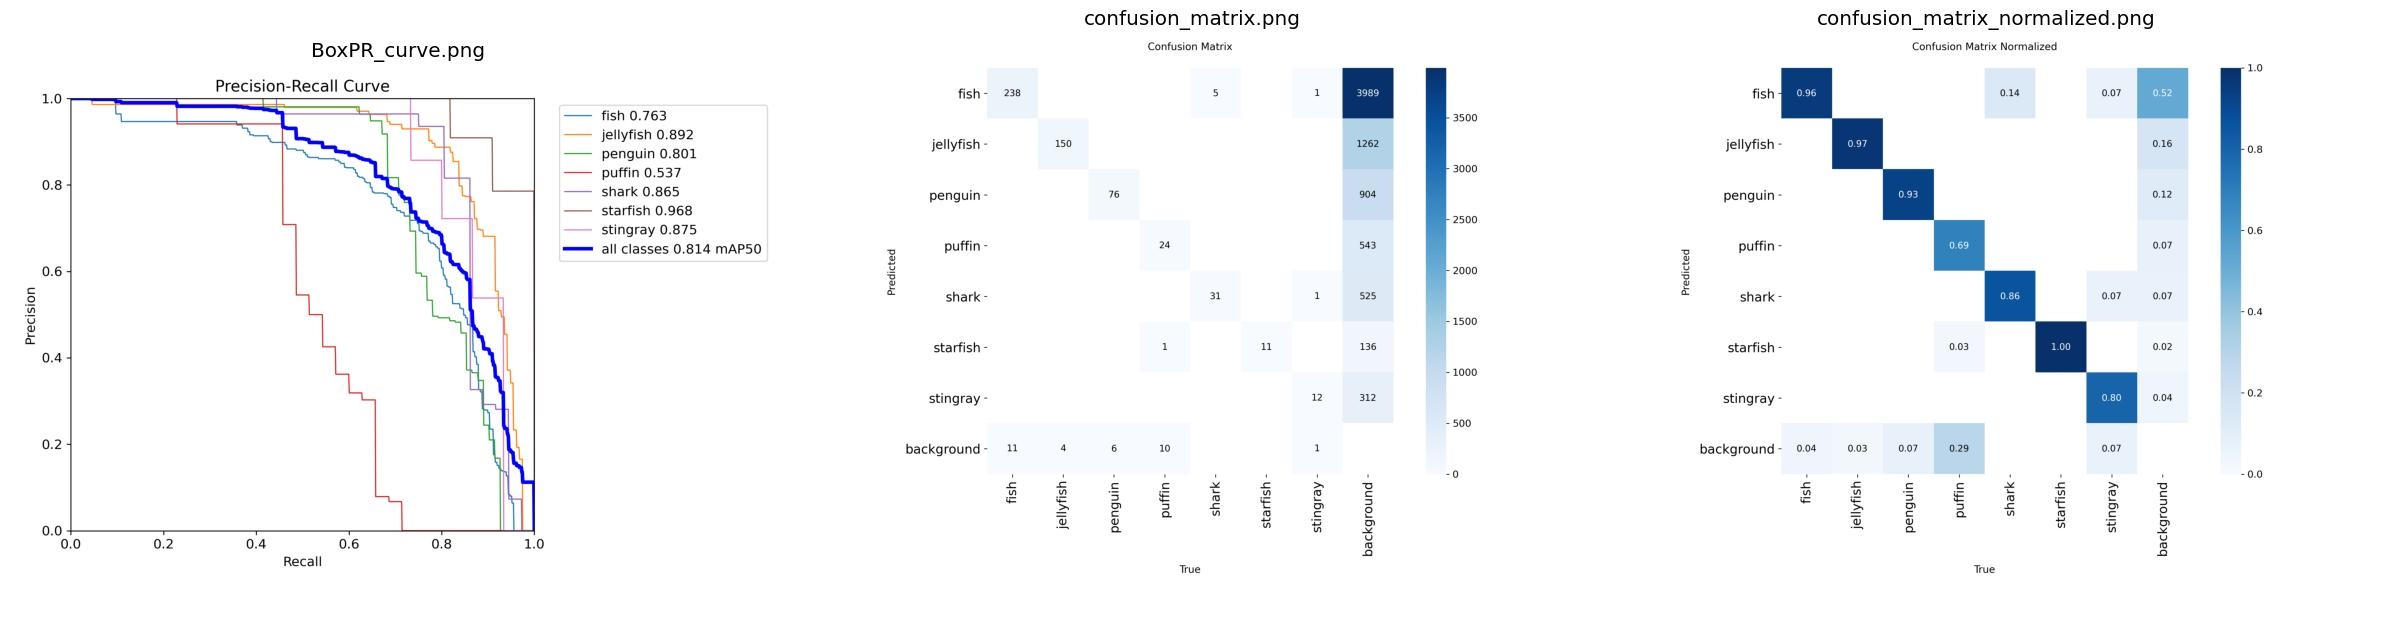

In [113]:
metrics_by_split = {}
for split_name in [s for s in ('val', 'test') if s in splits]:
    metrics_by_split[split_name] = val_metrics(best, split_name, f'eval_{split_name}')


def summarize(m):
    b = m.box
    per_class = {name: None for name in CLASSES}   # классы без объектов в сплите ultralytics пропускает
    for j, ci in enumerate(b.ap_class_index):
        p, r, ap50, ap = b.class_result(j)
        per_class[CLASSES[int(ci)]] = dict(precision=float(p), recall=float(r), ap50=float(ap50), ap50_95=float(ap))
    return dict(map50=float(b.map50), map50_95=float(b.map), precision=float(b.mp), recall=float(b.mr), per_class=per_class)


for split_name, m in metrics_by_split.items():
    s = summarize(m)
    print(f'== {split_name}: mAP50 {s["map50"]:.4f}, mAP50-95 {s["map50_95"]:.4f}, P {s["precision"]:.4f}, R {s["recall"]:.4f}')
    for name, v in s['per_class'].items():
        if v is not None:
            print(f'   {name:<10} P {v["precision"]:.3f}  R {v["recall"]:.3f}  AP50 {v["ap50"]:.3f}  AP50-95 {v["ap50_95"]:.3f}')

FINAL = {**summarize(metrics_by_split[FINAL_SPLIT]), 'split': FINAL_SPLIT}

# сверка: свой mAP50 по предсказаниям predict_records (conf=0.001) против ultralytics
final_preds = predict_records(best, records[FINAL_SPLIT], conf=0.001)
own_map50, own_aps = evaluate_map50(final_preds, records[FINAL_SPLIT], len(CLASSES))
FINAL['map50_own'] = float(own_map50)
print(f'\n{FINAL_SPLIT}: mAP50 ultralytics {FINAL["map50"]:.4f} vs свой evaluate_map50 {own_map50:.4f}')

# PR-кривая и confusion matrix, которые сохранил ultralytics
vd = Path(metrics_by_split[FINAL_SPLIT].save_dir)
files = [next(vd.glob('*PR_curve.png'), None), vd / 'confusion_matrix.png', vd / 'confusion_matrix_normalized.png']
fig, axes = plt.subplots(1, 3, figsize=(24, 8))
for ax, f in zip(axes, files):
    if f is not None and Path(f).exists():
        ax.imshow(plt.imread(f))
        ax.set_title(Path(f).name)
    ax.set_axis_off()
plt.tight_layout()
plt.show()

In [114]:
assert 'FINAL' in globals(), 'сначала заполните FINAL в ячейке выше'
assert {'map50', 'map50_95', 'precision', 'recall', 'per_class'} <= set(FINAL)
assert 0 <= FINAL['map50_95'] <= FINAL['map50'] <= 1
{k: (round(v, 4) if isinstance(v, float) else v) for k, v in FINAL.items() if k != 'per_class'}

{'map50': 0.8144,
 'map50_95': 0.5017,
 'precision': 0.8978,
 'recall': 0.7228,
 'split': 'test',
 'map50_own': 0.8092}

**Ответ:**

На тестовой выборке модель получила mAP50 = 0.8144 и mAP50-95 = 0.5017, precision = 0.8978 и recall = 0.7228. Это означает, что модель достаточно точно определяет найденные объекты, но при этом пропускает часть объектов.

Хуже всего модель распознаёт класс **puffin**: его AP50 составляет 0.537, а AP50-95 — 0.274. Также относительно низкий AP50-95 у penguin (0.353). Возможные причины — небольшое количество примеров этих классов, разнообразие внешнего вида объектов, их размер на изображениях и визуальное сходство с другими классами. Лучше всего модель распознаёт starfish (AP50 = 0.968) и jellyfish (AP50 = 0.892).

Confusion matrix показывает, какие классы модель путает между собой и какие объекты пропускает. Строка/столбец background отражает ошибки, связанные с фоном: ложные обнаружения объектов там, где их нет, и пропущенные объекты, для которых модель не нашла подходящего предсказания. По матрице также можно определить, какие именно классы чаще всего путаются между собой.

mAP50-95 заметно ниже mAP50 (0.5017 против 0.8144), потому что mAP50 учитывает обнаружение объекта при IoU от 0.5, а mAP50-95 усредняет AP по более строгим порогам IoU от 0.5 до 0.95. Поэтому второй показатель сильнее зависит от точности расположения и размера предсказанных рамок. Модель часто находит нужный объект, но не всегда достаточно точно очерчивает его границы.

Собственная реализация evaluate_map50 дала 0.8092 против 0.8144 у Ultralytics. Разница составляет всего 0.0052, то есть результаты хорошо совпадают. Небольшое расхождение может быть связано с различиями в обработке предсказаний, сопоставлении боксов с объектами и вычислении AP.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

mAP одним числом не говорит, что именно не так. Разложите ошибки модели на val по категориям своим кодом:

1. `box_iou_np(a, b)` - матрица IoU `(n, m)` для боксов xyxy на numpy
2. `categorize_predictions(pred, gt)` - категория для каждого предсказания одной картинки и список пропущенных объектов. Предсказания обходятся по убыванию score:
   - `'tp'` - тот же класс и IoU >= 0.5 с еще не найденным gt (этот gt становится найденным, берется gt с максимальным IoU)
   - иначе `'class'` (ошибка класса) - IoU >= 0.5 с gt другого класса
   - иначе `'localization'` (ошибка локализации) - тот же класс и IoU в [0.1, 0.5) с еще не найденным gt
   - иначе `'background'` (лишний бокс) - фон или дубль уже найденного объекта
   - `missed` (пропуск) - индексы gt, которые не стали tp и к которым не привязана ошибка класса или локализации (привязывается gt с максимальным IoU)
3. Посчитайте категории на val при `conf >= CONF_ERRORS`, доли и разбивку по классам, заполните `ERRORS = {категория: число}`. Покажите глазами 5+ примеров ошибок разных категорий: разметка и предсказания на одной картинке

**Вопрос.** Какая категория ошибок главная? Это ошибки модели или разметки (посмотрите на примеры)? Что бы вы сделали, чтобы уменьшить главную категорию?

In [115]:
CONF_ERRORS = 0.001 if FAST_MODE else 0.25   # порог уверенности для разбора ошибок (0.25 - как в model.predict);
# в FAST_MODE модель почти не обучена (все score ~0.003), низкий порог нужен только для проверки кода
ERROR_TYPES = ('tp', 'class', 'localization', 'background', 'missed')


def box_iou_np(a, b):
    # a: (n, 4), b: (m, 4) xyxy -> IoU (n, m); пустые входы -> массив формы (n, m)
    a = np.asarray(a, dtype=np.float64).reshape(-1, 4)
    b = np.asarray(b, dtype=np.float64).reshape(-1, 4)
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    lt = np.maximum(a[:, None, :2], b[None, :, :2])
    rb = np.minimum(a[:, None, 2:], b[None, :, 2:])
    wh = np.clip(rb - lt, 0, None)
    inter = wh[..., 0] * wh[..., 1]
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    union = area_a[:, None] + area_b[None, :] - inter
    return np.where(union > 0, inter / np.maximum(union, 1e-12), 0.0)


def categorize_predictions(pred, gt, iou_hit=0.5, iou_loc=0.1):
    # pred: dict(boxes, scores, labels), gt: dict(boxes, labels) одной картинки
    # -> (список категорий предсказаний в исходном порядке, список индексов пропущенных gt)
    pb = np.asarray(pred['boxes'], dtype=np.float64).reshape(-1, 4)
    ps = np.asarray(pred['scores'], dtype=np.float64).reshape(-1)
    pl = np.asarray(pred['labels']).reshape(-1)
    gb = np.asarray(gt['boxes'], dtype=np.float64).reshape(-1, 4)
    gl = np.asarray(gt['labels']).reshape(-1)
    ious = box_iou_np(pb, gb)
    found = np.zeros(len(gb), dtype=bool)   # gt, найденный как tp
    bound = np.zeros(len(gb), dtype=bool)   # gt, к которому привязана ошибка класса / локализации
    cats = ['background'] * len(pb)
    for i in np.argsort(-ps, kind='stable'):
        row = ious[i]
        same = gl == pl[i]
        cand = np.where(same & ~found & (row >= iou_hit))[0]
        if len(cand):
            found[cand[row[cand].argmax()]] = True
            cats[i] = 'tp'
            continue
        cand = np.where(~same & (row >= iou_hit))[0]
        if len(cand):
            bound[cand[row[cand].argmax()]] = True
            cats[i] = 'class'
            continue
        cand = np.where(same & ~found & (row >= iou_loc) & (row < iou_hit))[0]
        if len(cand):
            bound[cand[row[cand].argmax()]] = True
            cats[i] = 'localization'
    missed = [int(j) for j in np.where(~found & ~bound)[0]]
    return cats, missed

In [116]:
rng = np.random.default_rng(0)
a, b = rng.uniform(0, 50, (7, 2)), rng.uniform(0, 50, (5, 2))
a, b = np.concatenate([a, a + rng.uniform(1, 30, (7, 2))], 1), np.concatenate([b, b + rng.uniform(1, 30, (5, 2))], 1)
assert np.allclose(box_iou_np(a, b), box_iou(torch.tensor(a), torch.tensor(b)).numpy(), atol=1e-6)
assert box_iou_np(np.zeros((0, 4)), b).shape == (0, 5) and box_iou_np(a, np.zeros((0, 4))).shape == (7, 0)

gt = dict(boxes=np.array([[0, 0, 10, 10], [20, 20, 30, 30], [50, 50, 60, 60], [80, 80, 90, 90]], dtype=float),
          labels=np.array([0, 0, 1, 1]))
pred = dict(boxes=np.array([[0, 0, 10, 10],          # tp: gt 0
                            [0, 0, 10, 10.5],        # дубль gt 0 -> background
                            [20, 20, 26, 26],        # IoU 0.36 с gt 1 -> localization
                            [50, 50, 60, 60],        # класс 0 на gt 2 класса 1 -> class
                            [100, 100, 110, 110]],   # фон -> background
                           dtype=float),
            scores=np.array([0.9, 0.8, 0.7, 0.6, 0.5]), labels=np.array([0, 0, 0, 0, 1]))
cats, missed = categorize_predictions(pred, gt)
assert list(cats) == ['tp', 'background', 'localization', 'class', 'background'], cats
assert list(missed) == [3], missed

pred2 = dict(boxes=np.array([[0, 0, 10, 10], [1, 0, 10, 10]], dtype=float), scores=np.array([0.3, 0.9]), labels=np.array([0, 0]))
cats, missed = categorize_predictions(pred2, dict(boxes=gt['boxes'][:1], labels=gt['labels'][:1]))
assert list(cats) == ['background', 'tp'] and list(missed) == [], (cats, missed)   # порядок по score, а не по списку

empty = dict(boxes=np.zeros((0, 4)), scores=np.zeros(0), labels=np.zeros(0, dtype=np.int64))
cats, missed = categorize_predictions(empty, gt)
assert list(cats) == [] and list(missed) == [0, 1, 2, 3]
cats, missed = categorize_predictions(pred, dict(boxes=np.zeros((0, 4)), labels=np.zeros(0, dtype=np.int64)))
assert list(cats) == ['background'] * 5 and list(missed) == []
print('box_iou_np / categorize_predictions: ok')

box_iou_np / categorize_predictions: ok


In [117]:
print(CLASSES, category_to_label)
print(max(int(r['labels'].max()) for r in records['val'] if len(r['labels'])), len(CLASSES))

['fish', 'jellyfish', 'penguin', 'puffin', 'shark', 'starfish', 'stingray'] {1: 0, 2: 1, 3: 2, 4: 3, 5: 4, 6: 5, 7: 6}
6 7


val: 127 картинок, 909 объектов, 991 предсказаний при conf >= 0.25
  tp               721  (72.8% от числа предсказаний)
  class             29  (2.9% от числа предсказаний)
  localization      42  (4.2% от числа предсказаний)
  background       199  (20.1% от числа предсказаний)
  missed           135  (14.9% от числа объектов)

разбивка по классам:
  класс                   tp         class  localization    background        missed
  fish                   377            10            12           118            64
  jellyfish              140             0            10            27             8
  penguin                 80             2            11            30            15
  puffin                  39             1             8            13            28
  shark                   38            10             1             4            12
  starfish                20             1             0             2             3
  stingray                27             5          

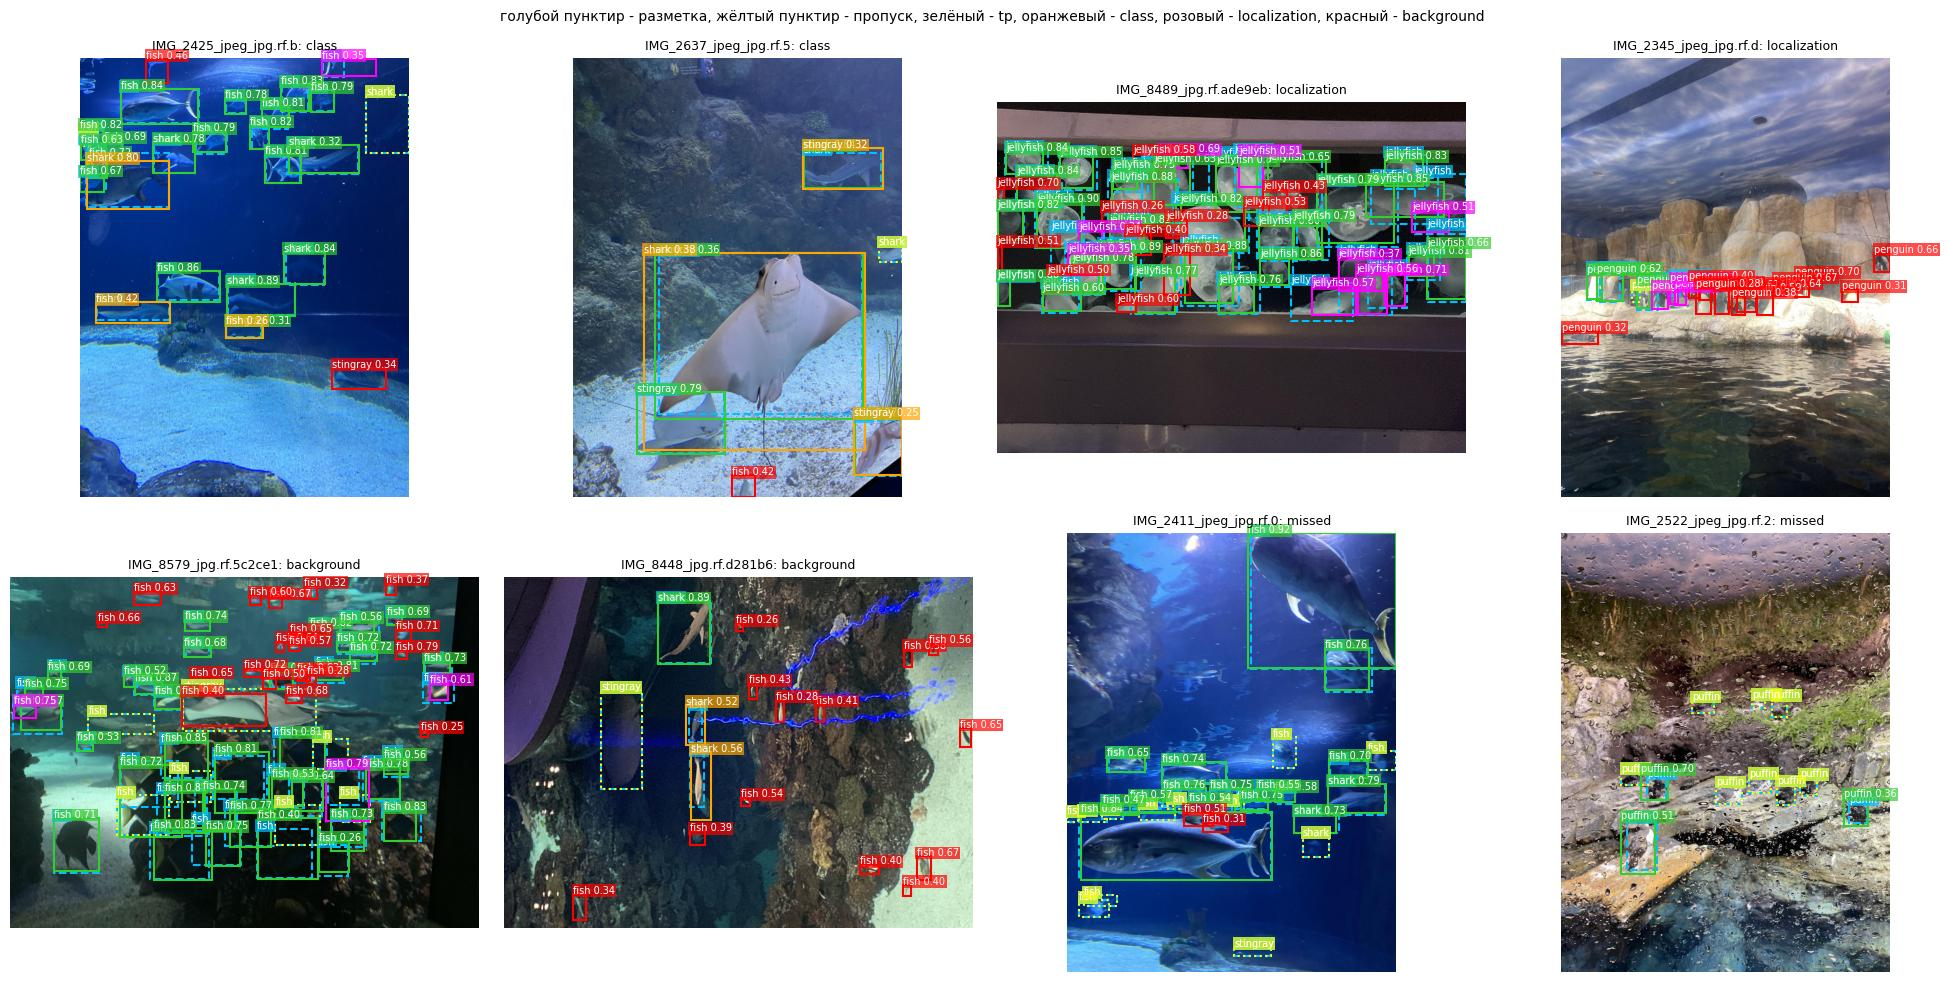

{'tp': 721, 'class': 29, 'localization': 42, 'background': 199, 'missed': 135}

In [118]:
val_recs = records['val']
val_preds = predict_records(best, val_recs, conf=CONF_ERRORS)

ERRORS = {k: 0 for k in ERROR_TYPES}
by_class = {k: np.zeros(len(CLASSES), dtype=int) for k in ERROR_TYPES}
per_image = []
for p, g in zip(val_preds, val_recs):
    cats, missed = categorize_predictions(p, g)
    per_image.append((cats, missed))
    for c, lbl in zip(cats, p['labels']):
        ERRORS[c] += 1
        by_class[c][int(lbl)] += 1
    for j in missed:
        ERRORS['missed'] += 1
        by_class['missed'][int(g['labels'][j])] += 1

n_pred = sum(len(p['labels']) for p in val_preds)
n_gt = sum(len(r['labels']) for r in val_recs)
print(f'val: {len(val_recs)} картинок, {n_gt} объектов, {n_pred} предсказаний при conf >= {CONF_ERRORS}')
for k in ERROR_TYPES:
    denom, what = (n_gt, 'объектов') if k == 'missed' else (n_pred, 'предсказаний')
    print(f'  {k:<13} {ERRORS[k]:>6}  ({ERRORS[k] / max(denom, 1):.1%} от числа {what})')

print('\nразбивка по классам:')
print(f'  {"класс":<12}' + ''.join(f'{k:>14}' for k in ERROR_TYPES))
for ci, name in enumerate(CLASSES):
    print(f'  {name:<12}' + ''.join(f'{by_class[k][ci]:>14}' for k in ERROR_TYPES))

# примеры: по 2 картинки с наибольшим числом ошибок каждой категории
chosen = []
for cat in ('class', 'localization', 'background', 'missed'):
    counts_img = [(len(m) if cat == 'missed' else cs.count(cat), i) for i, (cs, m) in enumerate(per_image)]
    for n_err, i in sorted(counts_img, reverse=True)[:2]:
        if n_err > 0 and (cat, i) not in chosen and i not in [c[1] for c in chosen]:
            chosen.append((cat, i))

CAT_COLORS = {'tp': 'limegreen', 'class': 'orange', 'localization': 'magenta', 'background': 'red'}
ncols = 4
nrows = max(1, math.ceil(len(chosen) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 5 * nrows), squeeze=False)
for ax in axes.ravel():
    ax.set_axis_off()
for ax, (cat, i) in zip(axes.ravel(), chosen):
    r, p = val_recs[i], val_preds[i]
    cats, missed = per_image[i]
    img = np.asarray(Image.open(r['image']).convert('RGB'))
    draw_boxes(ax, img, r['boxes'], r['labels'], CLASSES, color='deepskyblue', linestyle='--')   # разметка
    if missed:
        draw_boxes(ax, None, r['boxes'][missed], r['labels'][missed], CLASSES, color='yellow', linestyle=':')   # пропуски
    for c, col in CAT_COLORS.items():
        idx = [k for k, cc in enumerate(cats) if cc == c]
        if idx:
            draw_boxes(ax, None, p['boxes'][idx], p['labels'][idx], CLASSES, scores=p['scores'][idx], color=col)
    ax.set_title(f'{Path(r["image"]).name[:22]}: {cat}', fontsize=9)
plt.suptitle('голубой пунктир - разметка, жёлтый пунктир - пропуск, зелёный - tp, оранжевый - class, '
             'розовый - localization, красный - background', fontsize=10)
plt.tight_layout()
plt.show()
ERRORS

**Ответ:**

Главная категория ошибок среди предсказаний — **background**: 199 случаев (20.1% всех предсказаний при conf ≥ 0.25). Это лишние рамки, которые не соответствуют объектам разметки, в том числе дубли уже найденных объектов. Также заметны пропуски: 135 объектов (14.9% от общего числа объектов). Ошибок класса значительно меньше — 29, ошибок локализации — 42.

По примерам видно, что ошибки связаны не только с самой моделью, но и, возможно, с качеством разметки. Некоторые красные предсказания выглядят как реальные животные, которым не соответствует размеченный объект: это может указывать на неполную разметку. При этом встречаются и действительно лишние или дублирующие рамки, особенно на изображениях с большим количеством рыб и медуз. Больше всего ошибок background приходится на класс fish — 118 случаев.

Чтобы уменьшить число лишних предсказаний, я бы попробовал добавить в обучающую выборку сложные отрицательные примеры, улучшить и проверить разметку, а также поэкспериментировать с порогом confidence и параметрами NMS. Повышение confidence может убрать часть ложных срабатываний, но при этом способно увеличить количество пропусков, поэтому нужно оценивать одновременно precision и recall.

## 5.2 Абляция (1 балл)

Одна абляция на ваш выбор, остальные гиперпараметры как в 4.1:

- `imgsz`: например 320 против 640 (особенно интересно для мелких объектов)
- заморозка backbone: аргумент `freeze=<число первых слоев>`, backbone - первые `len(arch.yaml['backbone'])` слоев
- размер модели: n против s

Заполните `ABLATION`: что меняли, значения, mAP50 / mAP50-95 на val для обоих вариантов, время обучения.

**Вопрос.** Что изменилось и почему? Стоит ли это изменение своей цены по времени и качеству?

In [119]:
ABL_IMGSZ = IMGSZ // 2
model_abl, RUN_TIMES['ablation'], abl_dir = train_yolo('ablation_imgsz', **{**TRAIN_ARGS, 'imgsz': ABL_IMGSZ})
best_abl = YOLO(abl_dir / 'weights' / 'best.pt')
m_abl = best_abl.val(data=str(DATA_YAML), split='val', imgsz=ABL_IMGSZ, batch=BATCH, device=DEVICE, workers=WORKERS,
                     project=str(RUNS.resolve()), name='eval_ablation', exist_ok=True, verbose=False)
m_base = metrics_by_split['val']

ABLATION = dict(
    changed='imgsz', values=[IMGSZ, ABL_IMGSZ], split='val',
    map50=[float(m_base.box.map50), float(m_abl.box.map50)],
    map50_95=[float(m_base.box.map), float(m_abl.box.map)],
    train_time_sec=[RUN_TIMES['train'], RUN_TIMES['ablation']],
)
for k, v in enumerate(ABLATION['values']):
    print(f'imgsz={v}: mAP50 {ABLATION["map50"][k]:.4f}, mAP50-95 {ABLATION["map50_95"][k]:.4f}, '
          f'обучение {ABLATION["train_time_sec"][k]:.0f} s')
ABLATION

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=data/yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=ablation_imgsz, nbs=64, nms=None, opset=None, optimize=False, optimizer

{'changed': 'imgsz',
 'values': [640, 320],
 'split': 'val',
 'map50': [0.7750269342811055, 0.6627467169916594],
 'map50_95': [0.4881855615497652, 0.3712939815032744],
 'train_time_sec': [519.2940179929992, 377.26082656900144]}

**Ответ:**

При уменьшении imgsz с 640 до 320 время обучения сократилось с 519 до 377 секунд (примерно на 27%), однако mAP50 снизился с 0.7750 до 0.6627, а mAP50-95 — с 0.4882 до 0.3713. Вероятная причина - при уменьшении изображения теряются детали и мелкие объекты занимают меньше пикселей, поэтому модели сложнее их обнаруживать и точно локализовать. Для данного датасета, содержащего объекты разного размера и плотные сцены, imgsz=640 оказался предпочтительнее. Экономия примерно 142 секунд не компенсирует настолько сильное падение качества, поэтому я бы оставила размер 640.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, ограничения эксперимента (размер val, один seed, качество разметки), что бы сделали дальше.

**Ответ:**

В работе я дообучила предобученную модель YOLO26n для детекции семи классов морских животных на датасете Aquarium Combined, содержащем 638 изображений. На тестовой выборке модель достигла mAP50 = 0.8144 и mAP50-95 = 0.5017, precision = 0.8978 и recall = 0.7228, то есть в целом модель достаточно хорошо обнаруживает объекты, хотя часть из них пропускает. Лучше всего распознаются starfish (AP50 = 0.968) и jellyfish (AP50 = 0.892), а наиболее проблемным оказался puffin (AP50 = 0.537). Анализ ошибок на validation показал 199 ложных предсказаний категории background и 135 пропущенных объектов; особенно много ложных срабатываний приходится на fish, а пропусков — на puffin. Эксперимент с уменьшением imgsz с 640 до 320 показал, что обучение стало быстрее примерно на 27%, но mAP50 снизился с 0.7750 до 0.6627, поэтому для этого датасета более высокое разрешение оказалось предпочтительнее. При этом результаты следует оценивать с учётом ограничений: датасет сравнительно небольшой, validation содержит только 127 изображений, эксперимент проведён с одним seed, а качество и полнота исходной разметки могут влиять на метрики. В дальнейшем я бы проверил разметку и добавил примеры проблемных классов, особенно puffin, попробовал аугментации для мелких объектов и повторил обучение с несколькими seed для проверки стабильности результатов.

### Сохранение результатов обязательной части

Ячейка сохраняет `artifacts/metrics.json` (общий формат ДЗ2), `artifacts/results.csv` и `artifacts/best.pt`. Выполняется и в FAST_MODE для проверки формата; при окончательном прогоне файлы перезаписываются с `fast_mode: false`. Каталог `artifacts/` сдается вместе с ноутбуком.

In [120]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
metrics = dict(
    track='cv', model=WEIGHTS,
    revision=f'ultralytics=={MODEL_INFO["ultralytics"]}; sha256={MODEL_INFO["sha256"]}',
    dataset=DATASET_NAME, classes=CLASSES,
    n_train=len(train_recs), n_val=len(records['val']), n_test=len(records['test']) if 'test' in records else None,
    params_total=int(sum(blocks.values())), baseline=BASELINE, final=FINAL, ablation=ABLATION, errors=ERRORS,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES['train'], fast_mode=FAST_MODE,
    train_args=TRAIN_ARGS, run_times=RUN_TIMES,
)
(artifact_dir / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2, allow_nan=False),
                                           encoding='utf-8')
shutil.copy(run_dir / 'results.csv', artifact_dir / 'results.csv')
shutil.copy(run_dir / 'weights' / 'best.pt', artifact_dir / 'best.pt')
print('Сохранено:', [p.name for p in sorted(artifact_dir.iterdir())])

Сохранено: ['best.pt', 'metrics.json', 'results.csv']


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за все бонусы вместе - не больше 4 баллов. Сравнения делайте на том же val, что и в 4.2.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых картинок (CVAT, Label Studio или Roboflow Annotate, экспорт сразу в YOLO-формат), например из другого источника того же домена или из неразмеченной части датасета. Добавьте их в train, переобучите с теми же `TRAIN_ARGS` и сравните метрики на прежнем val. Опишите, сколько времени заняла разметка и какие были спорные случаи. Разметку положите в репозиторий (`extra/images`, `extra/labels`).

**Вопрос.** Как изменились метрики и стоило ли это потраченного времени?

In [121]:
if '6.1' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Ответ:**

## 6.2 Другая архитектура: RT-DETR (1 балл)

Дообучите трансформерный детектор RT-DETR из ultralytics (`from ultralytics import RTDETR`, веса `rtdetr-l.pt`) на тех же данных и сравните с YOLO: mAP50, mAP50-95, число параметров, время обучения, задержка на картинку. RT-DETR тяжелее, при нехватке памяти уменьшите `batch`.

**Вопрос.** Что выиграли и что проиграли? Когда бы выбрали RT-DETR?

In [122]:
if '6.2' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Ответ:**

## 6.3 Устойчивость к сдвигу домена (1 балл)

Сделайте 2-3 искаженные копии val (затемнение, гауссов шум, сильное JPEG-сжатие или картинки из другого источника того же домена), разметка та же. Посчитайте mAP50 / mAP50-95 дообученной модели на каждой копии.

**Вопрос.** Какое искажение бьет сильнее всего и по каким классам? Какая аугментация при обучении могла бы помочь?

In [123]:
if '6.3' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Ответ:**

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте дообученную модель в ONNX (`best.export(format='onnx', imgsz=IMGSZ)`; ultralytics сам доставит `onnx`, но надежнее `%pip install onnx onnxruntime`) или ускорьте ее иначе (TensorRT, half precision, квантизация). Сравните задержку на картинку до и после (прогрев, одинаковые условия, укажите устройство) и проверьте, что mAP50 не упал.

**Вопрос.** Во сколько раз ускорилось, за счет чего, и сколько стоило в качестве?

In [124]:
if '6.4' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Ответ:**

## 6.5 Пороги (1 балл)

Посмотрите, как порог уверенности `conf` и порог IoU в NMS (`iou`) меняют precision, recall и mAP на val (сетка хотя бы 4 x 2). Учтите, что YOLO26 по умолчанию работает end-to-end без NMS: проверьте, влияет ли `iou` вообще, и сравните с `end2end=False` (ветка one2many + NMS).

**Вопрос.** Какой `conf` вы бы выбрали для своей задачи и почему? Почему mAP почти не зависит от `conf`, а P и R зависят сильно? Влияет ли `iou` в end-to-end режиме?

In [125]:
if '6.5' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Ответ:**